## Intelligent Customer Churn Prediction and Risk Analysis System



#### Project Overview

Customer churn refers to the situation where customers stop using a company's products or services.

In this project, I will develop a Machine Learning-based system that predicts whether a customer is likely to leave a company based on historical customer information.

The system will analyze customer demographics, account information, service usage, contract details, payment methods, and other relevant factors to identify customers who are at risk of leaving.

The main aim of this project is to understand and implement the complete Machine Learning lifecycle, starting from raw data collection and ending with predictions for new customers.



##  Problem Statement

Companies regularly lose customers for different reasons, such as high service charges, poor customer experience, contract issues, or better offers from competitors.

Losing customers can negatively affect business revenue and growth.

Therefore, companies need a way to identify customers who are likely to leave before they actually stop using their services.

In this project, I will use historical customer data to build a binary classification model that predicts customer churn.

The target variable will be:

- Yes: Customer has left the company.
- No: Customer has not left the company.

The model will also estimate the probability of churn and classify customers into different risk categories.



##  Dataset Information

For this project, I plan to use the IBM Telco Customer Churn dataset.

The dataset contains information about customers of a telecommunications company.

It includes different types of information:

- Customer demographics
- Customer tenure
- Contract information
- Internet and phone services
- Monthly charges
- Total charges
- Payment methods
- Customer churn status

The target column is `Churn`, which indicates whether a customer has left the company.

Before training any Machine Learning model, I will first understand the dataset, inspect its quality, and perform the required preprocessing.



##  Project Workflow

The project will follow these major steps:

1. Problem Understanding
2. Dataset Collection
3. Data Loading and Inspection
4. Data Cleaning
5. Exploratory Data Analysis
6. Feature Engineering
7. Data Preprocessing
8. Machine Learning Model Development
9. Model Evaluation and Optimization
10. Deep Learning Implementation
11. Model Explainability
12. Error Analysis and Reliability
13. New Customer Churn Prediction
14. Final Model Evaluation and Documentation


In [1]:
import numpy as np
import pandas as pd


Data Visualization Libraries



In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

#### Importing Machine Learning Libraries

I will use it for:

- Splitting the dataset into training, validation, and testing sets.
- Data preprocessing and feature scaling.
- Training classification algorithms.
- Evaluating model performance.
- Hyperparameter tuning and cross-validation.


In [3]:
import sklearn

print("Scikit-learn Version:", sklearn.__version__)

Scikit-learn Version: 1.7.2



##### Importing Deep Learning Library

TensorFlow is a Deep Learning framework that provides tools for building and training Neural Networks.

In this project, I will use TensorFlow/Keras to develop a binary classification Neural Network for customer churn prediction.


In [6]:
import tensorflow as tf
import google.protobuf

print("TensorFlow Version:", tf.__version__)
print("Protobuf Version:", google.protobuf.__version__)
print("TensorFlow imported successfully!")

TensorFlow Version: 2.20.0
Protobuf Version: 6.33.0
TensorFlow imported successfully!



##### Importing Additional Libraries

I will also use some additional Python libraries for handling warnings, saving trained models, and evaluating model performance.

These libraries will support different stages of the project.


In [8]:
import warnings
import os
import pickle
import time

warnings.filterwarnings("ignore")



#  Dataset Collection and Loading

##  Dataset Understanding

For this project, I will use the IBM Telco Customer Churn dataset.

This dataset contains customer information from a telecommunications company. It provides details about customer demographics, subscribed services, account information, payment methods, and churn status.

The dataset will help me understand customer behavior and identify patterns that may indicate whether a customer is likely to leave the company.

Before building any Machine Learning model, I will first load and examine the dataset to understand its structure and available features.



In [9]:


dataset_path = "dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv"

print("Dataset path:", dataset_path)

Dataset path: dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv



###  Loading the Dataset

In [11]:
df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!




### Displaying Initial Dataset Records

In [13]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



###  Checking Dataset Dimensions

I will use the shape attribute to identify the total number of rows and columns in the dataset.

- Rows represent individual customer records.
- Columns represent customer attributes and information.


In [14]:
print("Number of Customers:", df.shape[0])
print("Number of Features:", df.shape[1])

Number of Customers: 7043
Number of Features: 21



# Initial Dataset Understanding

#### Understanding the Dataset Structure


The dataset consists of customer records, where each row represents one customer and each column represents a particular customer attribute.

In this section, I will inspect the dataset columns, data types, number of records, and basic statistical information.



In [15]:
# Display all column names

print("Dataset Columns:\n")

for column in df.columns:
    print(column)

Dataset Columns:

customerID
gender
SeniorCitizen
Partner
Dependents
tenure
PhoneService
MultipleLines
InternetService
OnlineSecurity
OnlineBackup
DeviceProtection
TechSupport
StreamingTV
StreamingMovies
Contract
PaperlessBilling
PaymentMethod
MonthlyCharges
TotalCharges
Churn


In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 



### Identifying Numerical Features

Numerical features contain values that can be measured or used in mathematical calculations.

I will identify these columns to understand which features contain numerical information.


In [18]:
numerical_features = df.select_dtypes(include=['int64', 'float64']).columns

print("Numerical Features:\n")

for feature in numerical_features:
    print(feature)

print("\nTotal Numerical Features:", len(numerical_features))

Numerical Features:

SeniorCitizen
tenure
MonthlyCharges

Total Numerical Features: 3


###  Identifying Categorical Features

In [19]:
categorical_features = df.select_dtypes(include=['object', 'category']).columns

print("Categorical Features:\n")

for feature in categorical_features:
    print(feature)

print("\nTotal Categorical Features:", len(categorical_features))

Categorical Features:

customerID
gender
Partner
Dependents
PhoneService
MultipleLines
InternetService
OnlineSecurity
OnlineBackup
DeviceProtection
TechSupport
StreamingTV
StreamingMovies
Contract
PaperlessBilling
PaymentMethod
TotalCharges
Churn

Total Categorical Features: 18



### 8.6 Statistical Summary of Numerical Features

I will use the describe() function to generate a statistical summary of the numerical columns.

It provides:

- Count: Number of available values.
- Mean: Average value.
- Standard deviation: Spread of values.
- Minimum: Smallest value.
- 25%, 50%, 75%: Quartiles.
- Maximum: Largest value.

This summary will help me understand the distribution and range of numerical customer information.


In [21]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [22]:
df.describe(include='object')

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


In [23]:
# Display unique values in categorical columns

for column in categorical_features:
    print(f"\n{column}:")
    print(df[column].unique())


customerID:
['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']

gender:
['Female' 'Male']

Partner:
['Yes' 'No']

Dependents:
['No' 'Yes']

PhoneService:
['No' 'Yes']

MultipleLines:
['No phone service' 'No' 'Yes']

InternetService:
['DSL' 'Fiber optic' 'No']

OnlineSecurity:
['No' 'Yes' 'No internet service']

OnlineBackup:
['Yes' 'No' 'No internet service']

DeviceProtection:
['No' 'Yes' 'No internet service']

TechSupport:
['No' 'Yes' 'No internet service']

StreamingTV:
['No' 'Yes' 'No internet service']

StreamingMovies:
['No' 'Yes' 'No internet service']

Contract:
['Month-to-month' 'One year' 'Two year']

PaperlessBilling:
['Yes' 'No']

PaymentMethod:
['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']

TotalCharges:
['29.85' '1889.5' '108.15' ... '346.45' '306.6' '6844.5']

Churn:
['No' 'Yes']


In [24]:
# Check target variable values

print("Target Variable: Churn")

print("\nUnique Values:")
print(df['Churn'].unique())

print("\nClass Counts:")
print(df['Churn'].value_counts())

Target Variable: Churn

Unique Values:
['No' 'Yes']

Class Counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64



###  Initial Churn Distribution

I will calculate the percentage of customers in each churn category.

This will give me an initial understanding of the distribution of customers who have left and those who have stayed.

The class distribution will also help me identify whether the dataset may contain class imbalance.


In [25]:
churn_percentage = df['Churn'].value_counts(normalize=True) * 100

print("Churn Distribution (%):\n")

print(churn_percentage.round(2))

Churn Distribution (%):

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [26]:
# Check missing values in each column

missing_values = df.isnull().sum()

print("Missing Values in Each Column:\n")
print(missing_values)


Missing Values in Each Column:

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [27]:
# Calculate missing value percentage

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': missing_percentage
})

missing_summary

,Missing Values,Missing Percentage
customerID,0,0.0
gender,0,0.0
SeniorCitizen,0,0.0
Partner,0,0.0
Dependents,0,0.0
tenure,0,0.0
PhoneService,0,0.0
MultipleLines,0,0.0
InternetService,0,0.0
OnlineSecurity,0,0.0


In [28]:
# Check duplicate records

duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

Total Duplicate Records: 0



###  Checking Data Types

Each column should have an appropriate data type based on the information it contains.

For example:

- Customer tenure should be numerical.
- Monthly charges should be numerical.
- Contract type should be categorical.
- Churn should be categorical.

Incorrect data types may create problems during calculations and model preprocessing.

I will inspect the current data types of all columns.


In [29]:
data_types = pd.DataFrame({
    'Column': df.columns,
    'Data Type': df.dtypes.values
})

data_types

,Column,Data Type
0,customerID,object
1,gender,object
2,SeniorCitizen,int64
3,Partner,object
4,Dependents,object
5,tenure,int64
6,PhoneService,object
7,MultipleLines,object
8,InternetService,object
9,OnlineSecurity,object



###  Investigating TotalCharges Column

The TotalCharges column represents the total amount charged to a customer.

Since it contains numerical information, I expect it to have a numerical data type.

However, during initial dataset inspection, it may appear as an object data type.

I will inspect its unique values and check whether it contains empty strings or other unexpected entries before converting it into a numerical format.


In [30]:
print("TotalCharges Data Type:", df['TotalCharges'].dtype)

print("\nSample Values:")
print(df['TotalCharges'].head(15).tolist())

print("\nNumber of Empty Strings:")
print((df['TotalCharges'].astype(str).str.strip() == '').sum())

TotalCharges Data Type: object

Sample Values:
['29.85', '1889.5', '108.15', '1840.75', '151.65', '820.5', '1949.4', '301.9', '3046.05', '3487.95', '587.45', '326.8', '5681.1', '5036.3', '2686.05']

Number of Empty Strings:
11


In [31]:
# Inspect minimum and maximum numerical values

range_summary = pd.DataFrame({
    'Minimum': df[numerical_features].min(),
    'Maximum': df[numerical_features].max()
})

range_summary

,Minimum,Maximum
SeniorCitizen,0.00,1.00
tenure,0.00,72.00
MonthlyCharges,18.25,118.75



###  Data Quality Summary

I will combine the important data quality observations into a summary.

This will help me understand the overall condition of the original dataset and identify the areas that require cleaning in the next stage.


In [32]:
quality_summary = pd.DataFrame({
    'Metric': [
        'Total Rows',
        'Total Columns',
        'Missing Values',
        'Duplicate Rows',
        'Unique Customer IDs',
        'Numerical Columns',
        'Categorical Columns'
    ],
    'Value': [
        df.shape[0],
        df.shape[1],
        df.isnull().sum().sum(),
        df.duplicated().sum(),
        df['customerID'].nunique(),
        len(numerical_features),
        len(categorical_features)
    ]
})

quality_summary

,Metric,Value
0,Total Rows,7043
1,Total Columns,21
2,Missing Values,0
3,Duplicate Rows,0
4,Unique Customer IDs,7043
5,Numerical Columns,3
6,Categorical Columns,18



#  Data Cleaning and Handling Missing Values

Data cleaning is an important step in the Machine Learning lifecycle.

Raw datasets may contain missing values, incorrect data types, duplicate records, and unnecessary information.

These issues can affect data analysis and model performance.

In this section, I will clean the IBM Telco Customer Churn dataset by handling missing values, correcting data types, checking duplicate records, and preparing the dataset for further analysis.

I will also preserve the original dataset and perform cleaning operations on a separate copy.



###  Creating a Copy of the Original Dataset

Before performing data cleaning, I will create a copy of the original DataFrame.

This helps preserve the original dataset and allows me to compare the raw and cleaned data whenever required.

All further cleaning operations will be performed on the copied DataFrame named `df_clean`.


In [33]:
df_clean = df.copy()

print("Original Dataset Shape:", df.shape)
print("Working Dataset Shape:", df_clean.shape)

Original Dataset Shape: (7043, 21)
Working Dataset Shape: (7043, 21)


In [34]:
# Remove unnecessary spaces from column names

df_clean.columns = df_clean.columns.str.strip()

print("Updated Column Names:")
print(df_clean.columns.tolist())

Updated Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [35]:
# Check missing values

df_clean.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


###  Converting TotalCharges into Numerical Format

During dataset inspection, I observed that the TotalCharges column may be stored as an object data type even though it represents numerical customer charges.

Some records may contain empty strings instead of numerical values.

I will use Pandas to_numeric() with errors='coerce' to convert valid values into numerical format.

Any value that cannot be converted will automatically become NaN.

This will allow me to handle those missing values using an appropriate technique.


In [36]:
df_clean['TotalCharges'] = pd.to_numeric(
    df_clean['TotalCharges'],
    errors='coerce'
)

print("Updated Data Type:", df_clean['TotalCharges'].dtype)

print("\nMissing Values in TotalCharges:",
      df_clean['TotalCharges'].isnull().sum())

Updated Data Type: float64

Missing Values in TotalCharges: 11


In [37]:
# Display records with missing TotalCharges

df_clean[df_clean['TotalCharges'].isnull()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [38]:
# Check tenure for missing TotalCharges records

missing_total_charges = df_clean[
    df_clean['TotalCharges'].isnull()
]

print("Tenure Values of Missing Records:")
print(missing_total_charges['tenure'].value_counts())

Tenure Values of Missing Records:
tenure
0    11
Name: count, dtype: int64


In [39]:
# Replace missing TotalCharges with zero

df_clean['TotalCharges'] = df_clean['TotalCharges'].fillna(0)

print("Missing TotalCharges After Handling:",
      df_clean['TotalCharges'].isnull().sum())

Missing TotalCharges After Handling: 0


In [40]:
# Check and remove duplicate records

duplicate_count = df_clean.duplicated().sum()

print("Duplicate Records Found:", duplicate_count)

if duplicate_count > 0:
    df_clean = df_clean.drop_duplicates()
    print("Duplicate Records Removed:", duplicate_count)
else:
    print("No duplicate records found.")

Duplicate Records Found: 0
No duplicate records found.



###  Removing Unnecessary Customer Identifier

The customerID column contains unique identification numbers for individual customers.

It does not directly represent customer behavior or service usage.

Since it is an identifier rather than a meaningful predictive feature, I will remove it from the working dataset before Machine Learning.

The original dataset will still retain this information.


In [41]:
# Remove customerID column

if 'customerID' in df_clean.columns:
    df_clean = df_clean.drop(columns=['customerID'])

print("customerID column removed successfully.")
print("Updated Dataset Shape:", df_clean.shape)

customerID column removed successfully.
Updated Dataset Shape: (7043, 20)


In [42]:
# Inspect cleaned dataset

print("Cleaned Dataset Information:\n")

df_clean.info()

Cleaned Dataset Information:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMetho


### 10.12 Final Data Cleaning Summary

Finally, I will generate a summary of the cleaned dataset.

This will help me compare the original dataset with the cleaned dataset and understand the changes made during data cleaning.


In [43]:
# Generate final cleaning summary

cleaning_summary = pd.DataFrame({
    'Metric': [
        'Original Rows',
        'Cleaned Rows',
        'Original Columns',
        'Cleaned Columns',
        'Remaining Missing Values',
        'Remaining Duplicate Records'
    ],
    'Value': [
        df.shape[0],
        df_clean.shape[0],
        df.shape[1],
        df_clean.shape[1],
        df_clean.isnull().sum().sum(),
        df_clean.duplicated().sum()
    ]
})

cleaning_summary

,Metric,Value
0,Original Rows,7043
1,Cleaned Rows,7043
2,Original Columns,21
3,Cleaned Columns,20
4,Remaining Missing Values,0
5,Remaining Duplicate Records,22



###  Analyzing Customer Churn Distribution

The first step of EDA is to understand the distribution of the target variable.

The Churn column contains two categories:

- Yes: Customers who have left the company.
- No: Customers who are still using the company's services.

I will calculate the number of customers in each category to understand the overall churn distribution.


In [44]:
churn_counts = df_clean['Churn'].value_counts()

print("Customer Churn Distribution:\n")
print(churn_counts)

Customer Churn Distribution:

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [46]:
# Calculating percentage of each churn category

churn_percentages = (
    df_clean['Churn'].value_counts(normalize=True) * 100
)

print("Customer Churn Percentage:\n")
print(churn_percentages.round(2))

Customer Churn Percentage:

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64



###  Visualizing Customer Churn Distribution

Visualizations make it easier to understand the distribution of customer churn.

I will create a count plot to compare the number of customers who have left the company with those who have stayed.

This visualization will help identify whether the dataset contains class imbalance.


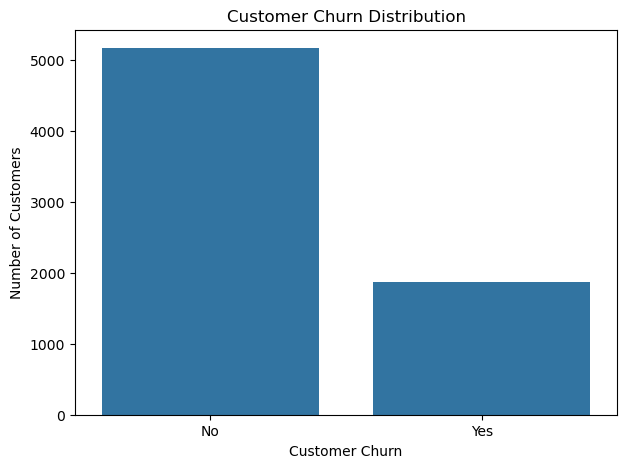

In [47]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x='Churn'
)

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

plt.show()


###  Visualizing Churn Percentage

I will also create a pie chart to understand the percentage contribution of each churn category.

This visualization provides a simple overview of the proportion of customers who have left and those who have stayed.


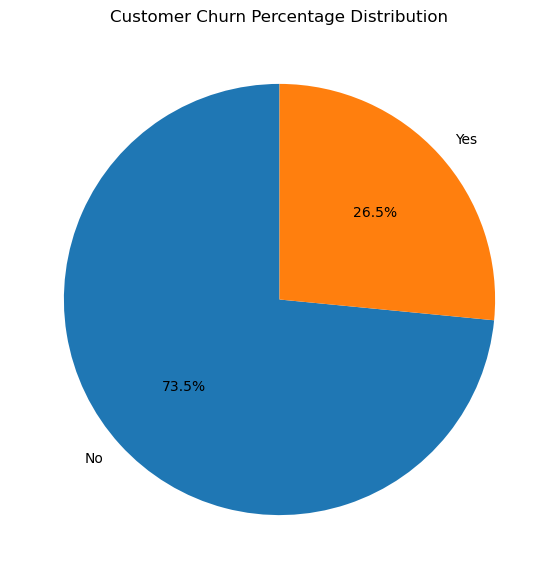

In [48]:
plt.figure(figsize=(7, 7))

plt.pie(
    churn_counts,
    labels=churn_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Customer Churn Percentage Distribution")

plt.show()


### Initial Observation

After analyzing the customer churn distribution, I will record the main observations.

I will identify which category contains more customers and whether the dataset has an imbalance between churned and non-churned customers.

These observations will help me understand the target variable before moving to feature-level analysis.



###  Numerical Feature Analysis

Numerical features contain measurable values that can be analyzed using statistical methods and visualizations.

In this section, I will analyze important numerical customer attributes such as tenure, MonthlyCharges, and TotalCharges.

I will use histograms and box plots to understand their distributions, identify unusual values, and observe differences between customers who have left the company and those who have stayed.


In [49]:
# Identify numerical columns from cleaned dataset

numerical_features = df_clean.select_dtypes(
    include=['int64', 'float64']
).columns

print("Numerical Features:")
print(numerical_features.tolist())

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']



###  Statistical Analysis of Numerical Features

I will generate descriptive statistics for numerical customer attributes.

This includes mean, median, standard deviation, minimum, maximum, and quartile values.

These statistics will help me understand the range and distribution of customer information.


In [50]:
df_clean[numerical_features].describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000



### Visualizing Numerical Feature Distributions

Histograms help us understand how numerical values are distributed.

I will create separate histograms for tenure, MonthlyCharges, and TotalCharges.

This will help me identify whether the values are evenly distributed, concentrated in particular ranges, or skewed.


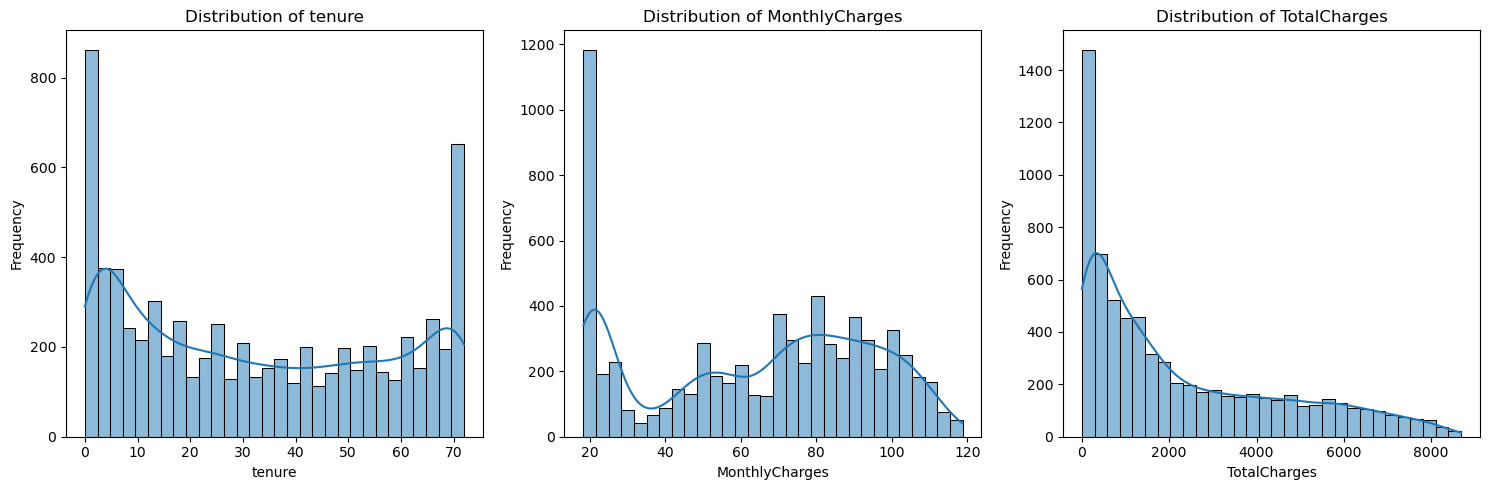

In [51]:
features_to_plot = [
    'tenure',
    'MonthlyCharges',
    'TotalCharges'
]

plt.figure(figsize=(15, 5))

for i, feature in enumerate(features_to_plot, 1):

    plt.subplot(1, 3, i)

    sns.histplot(
        data=df_clean,
        x=feature,
        bins=30,
        kde=True
    )

    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


###  Identifying Outliers Using Box Plots

Box plots provide a visual summary of numerical data.

They help identify the median, quartiles, spread of values, and potential outliers.

I will create box plots for the numerical features to understand their distributions and identify unusual observations.

Potential outliers will be investigated before deciding whether any treatment is required.


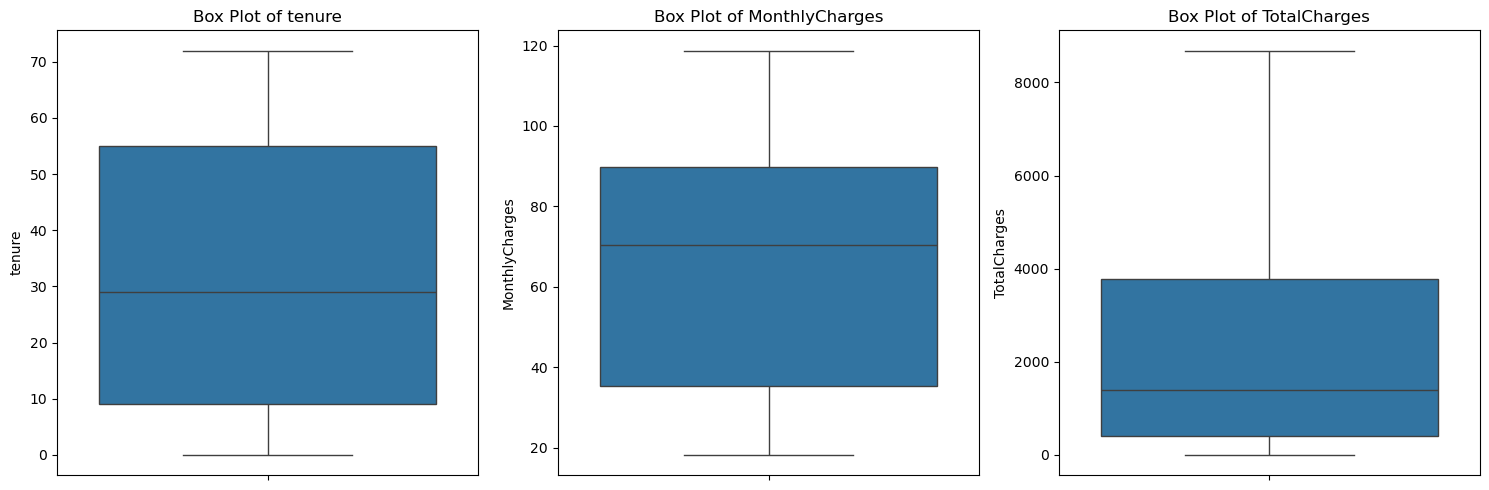

In [52]:
plt.figure(figsize=(15, 5))

for i, feature in enumerate(features_to_plot, 1):

    plt.subplot(1, 3, i)

    sns.boxplot(
        data=df_clean,
        y=feature
    )

    plt.title(f"Box Plot of {feature}")

plt.tight_layout()
plt.show()


### Relationship Between Customer Tenure and Churn

Customer tenure represents the total number of months a customer has stayed with the company.

I want to understand whether customers with shorter tenure are more likely to leave compared to long-term customers.

I will use a box plot to compare customer tenure across both churn categories.


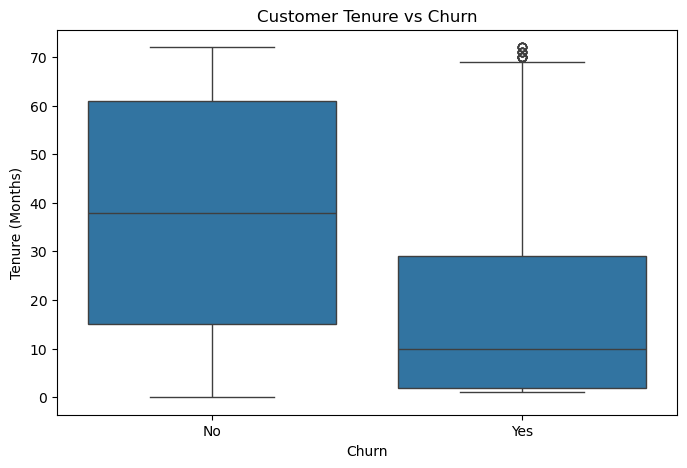

In [53]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x='Churn',
    y='tenure'
)

plt.title("Customer Tenure vs Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()


###  Relationship Between Monthly Charges and Churn

MonthlyCharges represents the monthly amount paid by each customer.

Higher service costs may influence customer decisions to leave a company.

I will compare monthly charges between churned and non-churned customers using a box plot.

This will help me understand whether monthly charges show any noticeable relationship with customer churn.


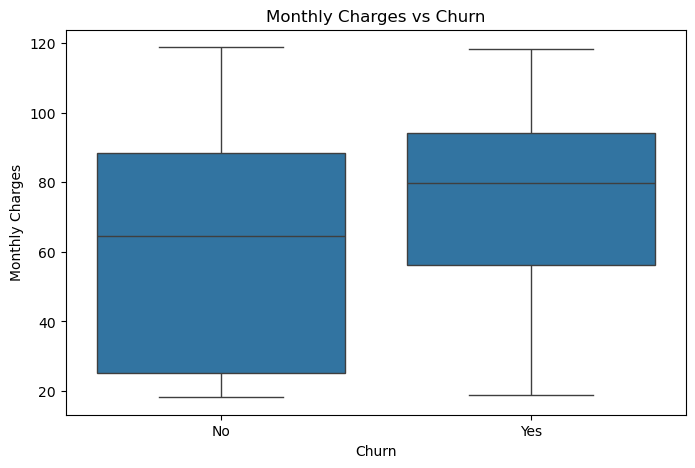

In [54]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x='Churn',
    y='MonthlyCharges'
)

plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

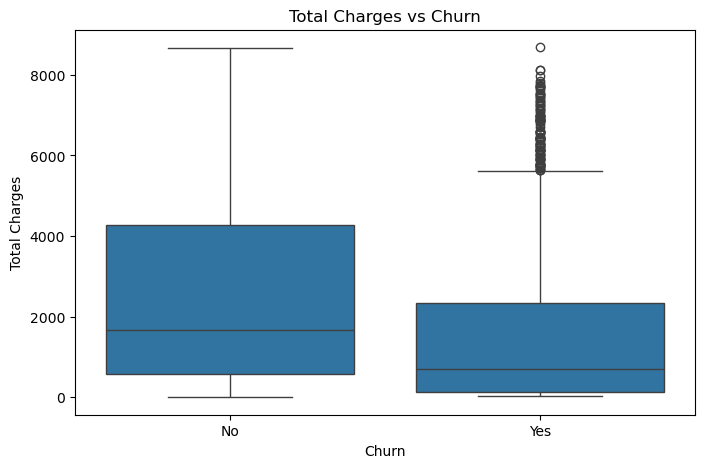

In [55]:
# Compare TotalCharges across churn categories

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x='Churn',
    y='TotalCharges'
)

plt.title("Total Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Total Charges")

plt.show()


###  Comparing Numerical Features by Churn Category

Visualizations help identify patterns, but numerical summaries provide additional information.

I will calculate the average tenure, MonthlyCharges, and TotalCharges for customers in each churn category.

This comparison will help me understand the differences between churned and non-churned customers.


In [57]:
churn_numeric_summary = df_clean.groupby('Churn')[
    features_to_plot
].mean()

churn_numeric_summary

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.569965,61.265124,2549.911442
Yes,17.979133,74.441332,1531.796094



###  Observations from Numerical Feature Analysis

After analyzing the numerical features, I will record the important observations.

I will focus on:

1. Customer tenure distribution.
2. Monthly charge distribution.
3. Total charge distribution.
4. Differences in tenure between churned and non-churned customers.
5. Differences in monthly charges between churned and non-churned customers.
6. Differences in total charges between churned and non-churned customers.

These observations will help identify numerical features that may be useful for predicting customer churn.



###  Identifying Categorical Features

In [58]:
categorical_features = df_clean.select_dtypes(
    include=['object', 'category']
).columns.tolist()

categorical_features.remove('Churn')

print("Categorical Features:\n")

for feature in categorical_features:
    print(feature)

print("\nTotal Categorical Features:", len(categorical_features))

Categorical Features:

gender
Partner
Dependents
PhoneService
MultipleLines
InternetService
OnlineSecurity
OnlineBackup
DeviceProtection
TechSupport
StreamingTV
StreamingMovies
Contract
PaperlessBilling
PaymentMethod

Total Categorical Features: 15


In [59]:
# Display category counts for each categorical feature

for feature in categorical_features:

    print(f"\nDistribution of {feature}:\n")

    print(df_clean[feature].value_counts())


Distribution of gender:

gender
Male      3555
Female    3488
Name: count, dtype: int64

Distribution of Partner:

Partner
No     3641
Yes    3402
Name: count, dtype: int64

Distribution of Dependents:

Dependents
No     4933
Yes    2110
Name: count, dtype: int64

Distribution of PhoneService:

PhoneService
Yes    6361
No      682
Name: count, dtype: int64

Distribution of MultipleLines:

MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

Distribution of InternetService:

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

Distribution of OnlineSecurity:

OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

Distribution of OnlineBackup:

OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

Distribution of DeviceProtection:

Devic


###  Visualizing Categorical Feature Distributions


Count plots help visualize the number of customers belonging to each category.

I will create count plots for the categorical features to understand their distributions.


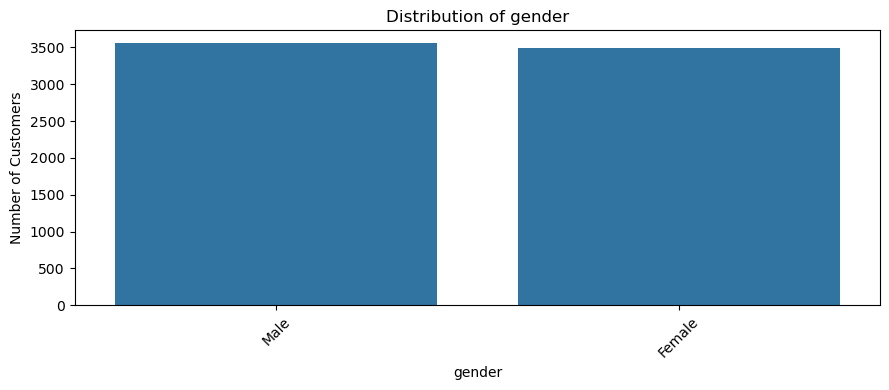

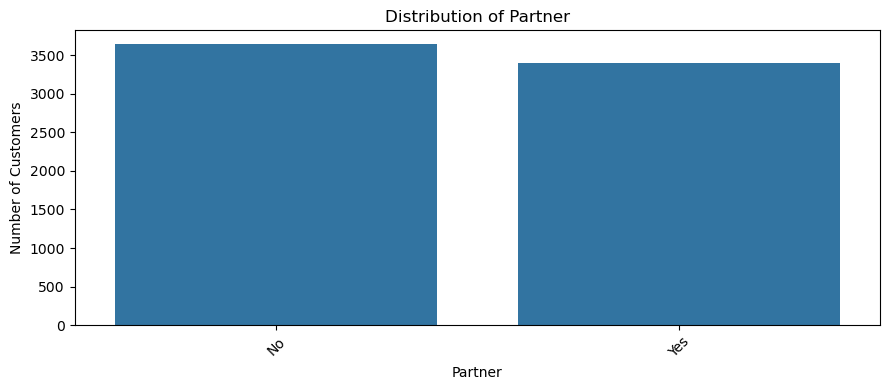

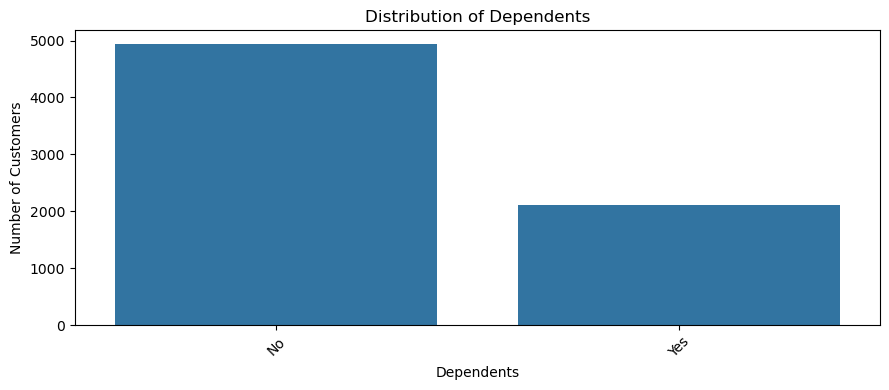

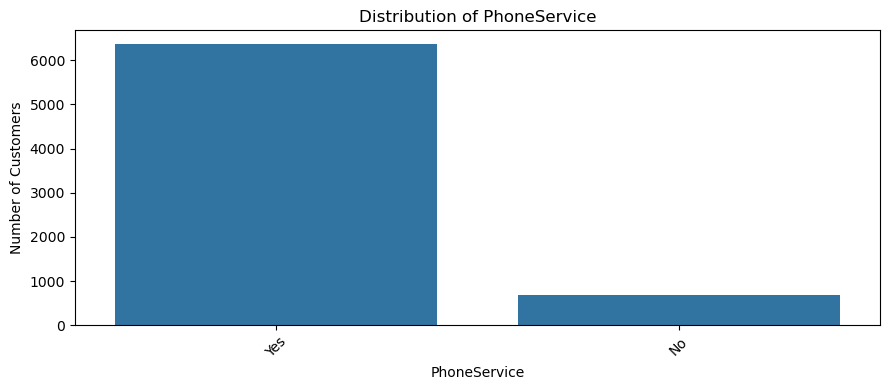

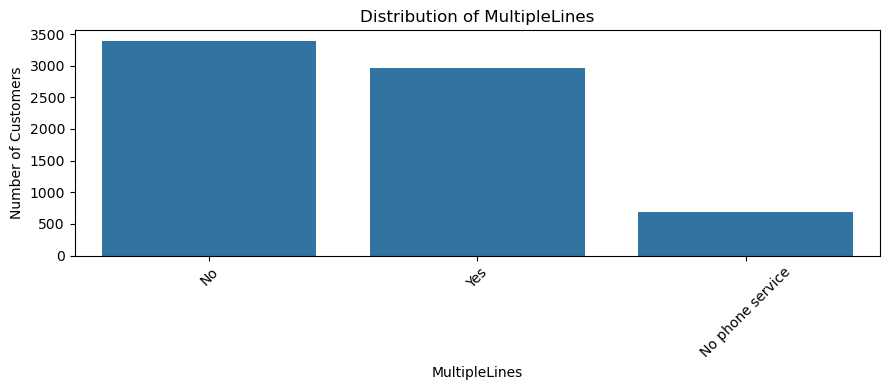

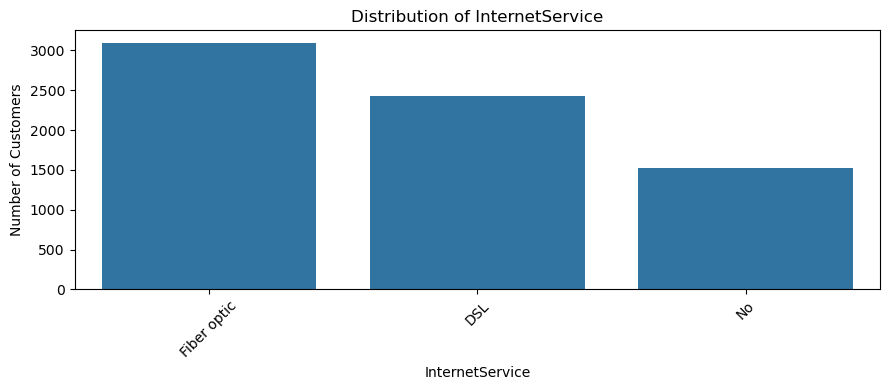

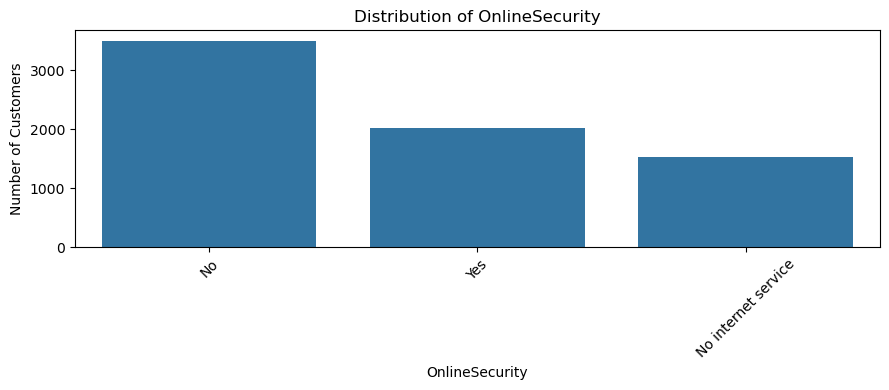

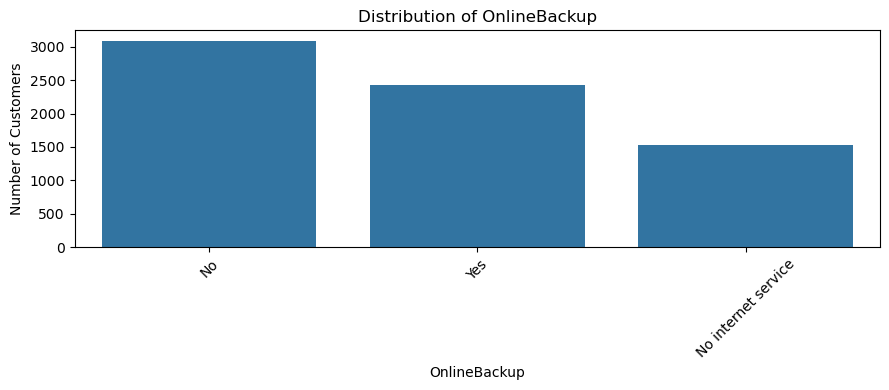

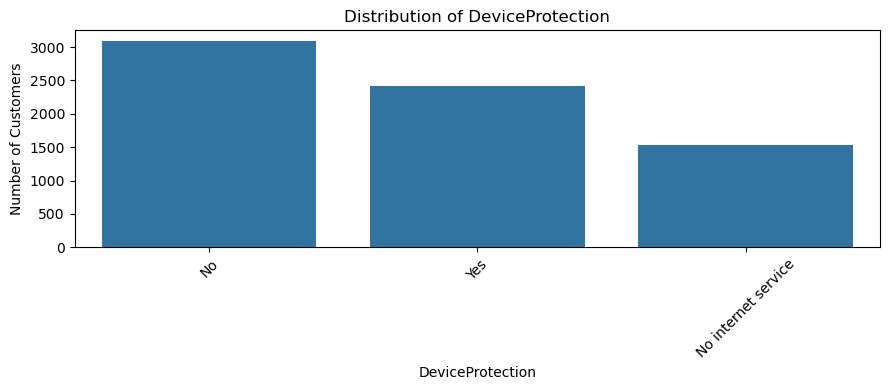

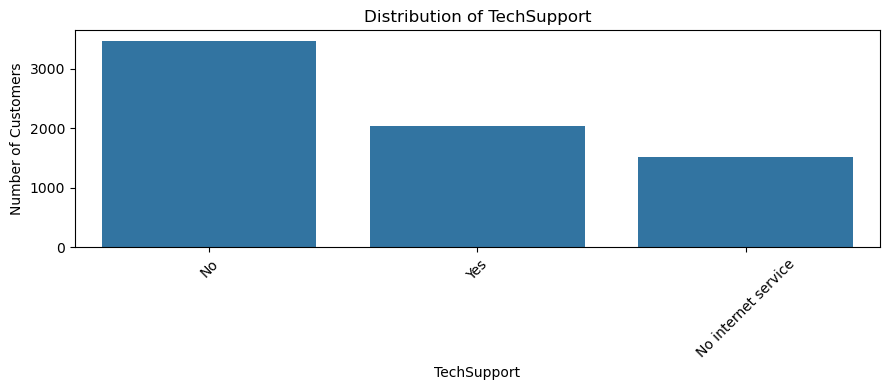

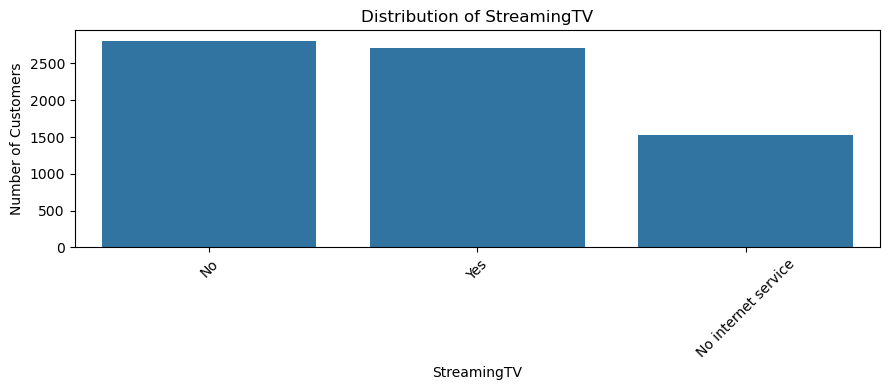

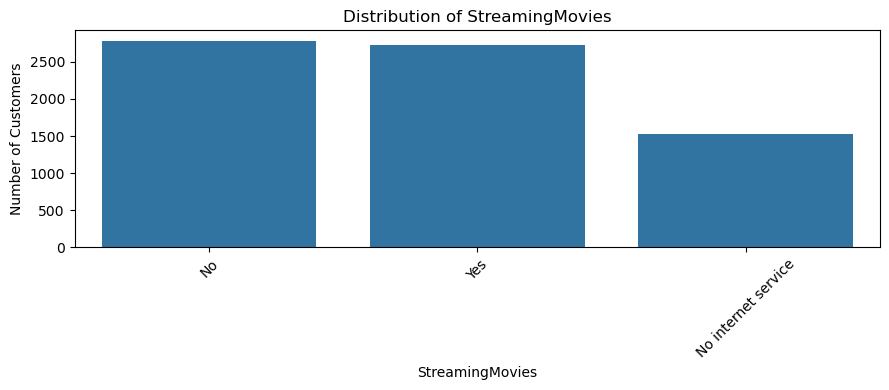

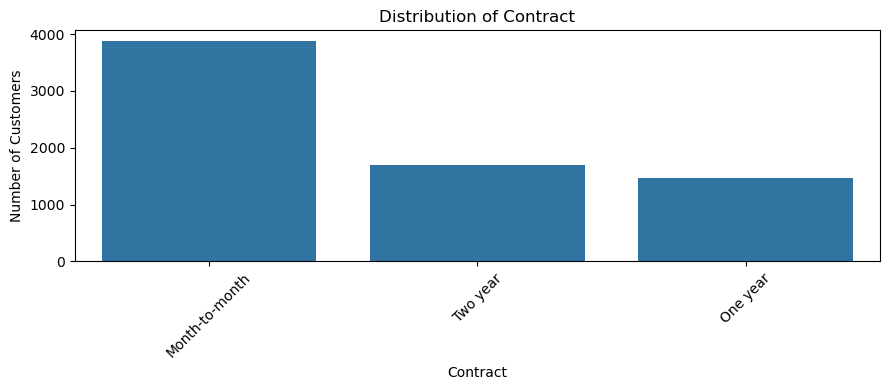

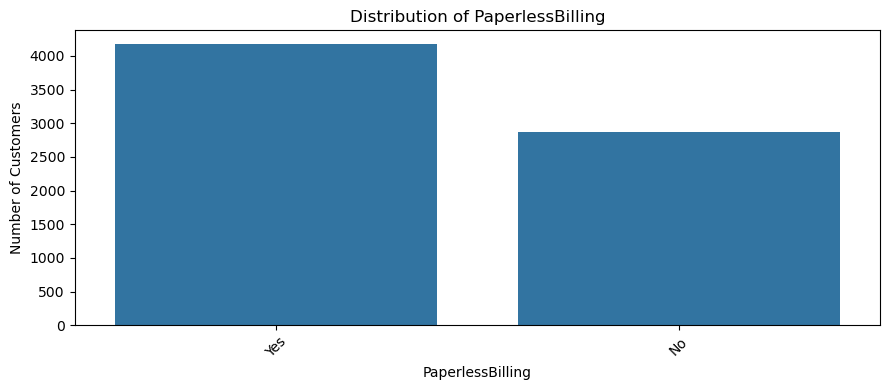

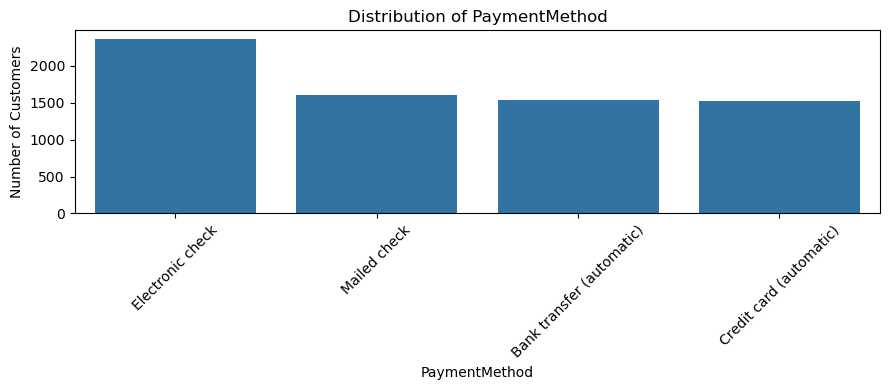

In [60]:
for feature in categorical_features:

    plt.figure(figsize=(9, 4))

    sns.countplot(
        data=df_clean,
        x=feature,
        order=df_clean[feature].value_counts().index
    )

    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Number of Customers")
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()


###  Visualizing Churn by Categorical Features

I will create count plots to compare churned and non-churned customers across categorical groups.

Using the hue parameter, I can display both churn categories within the same visualization.

This will help me identify differences in customer behavior across categories.


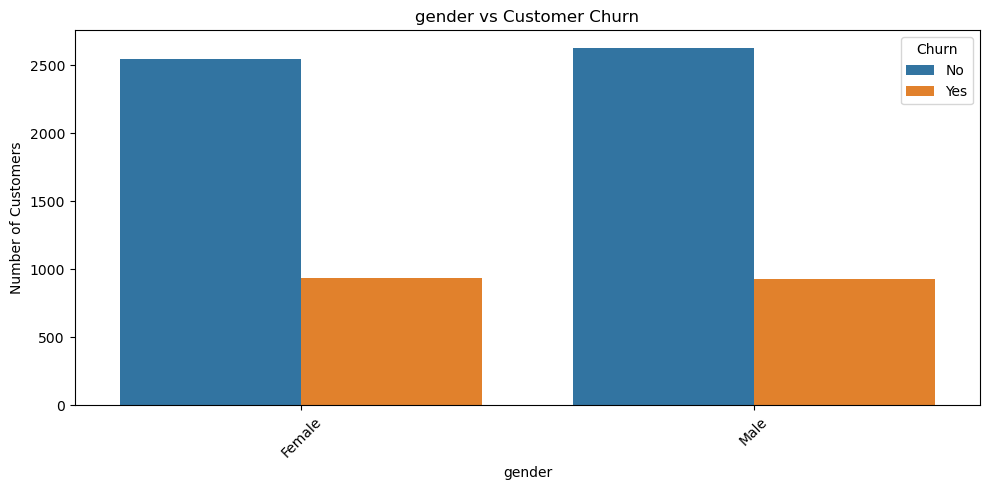

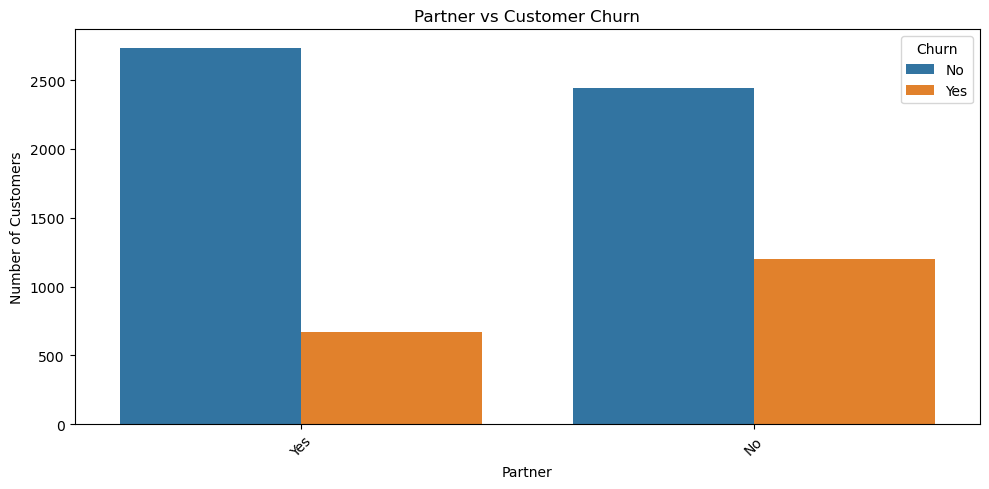

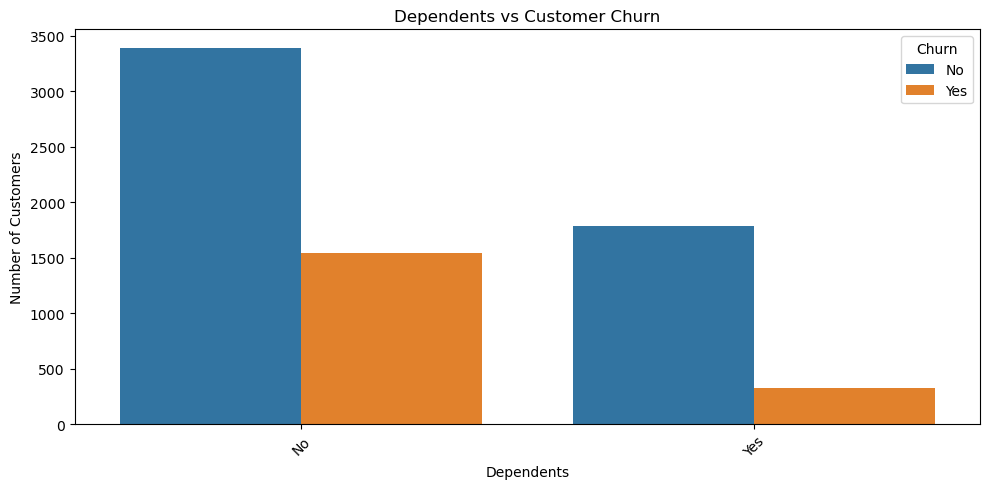

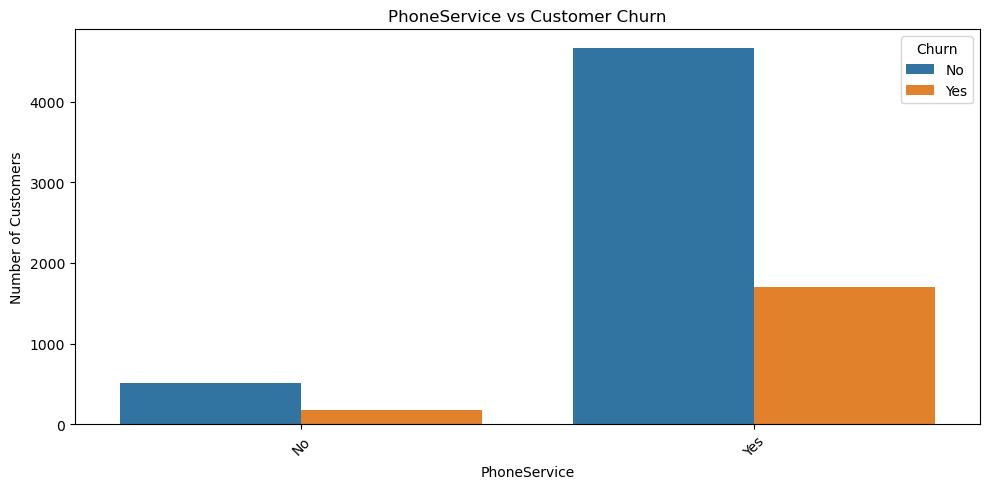

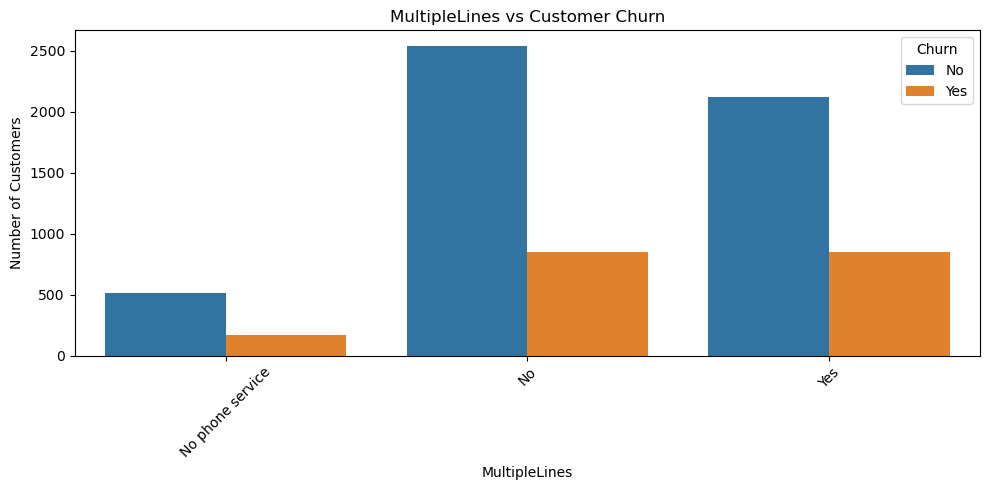

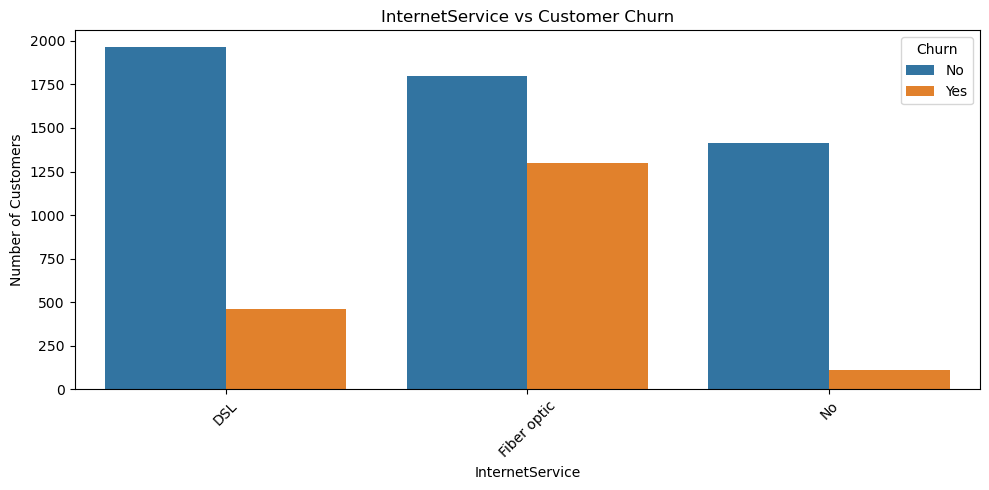

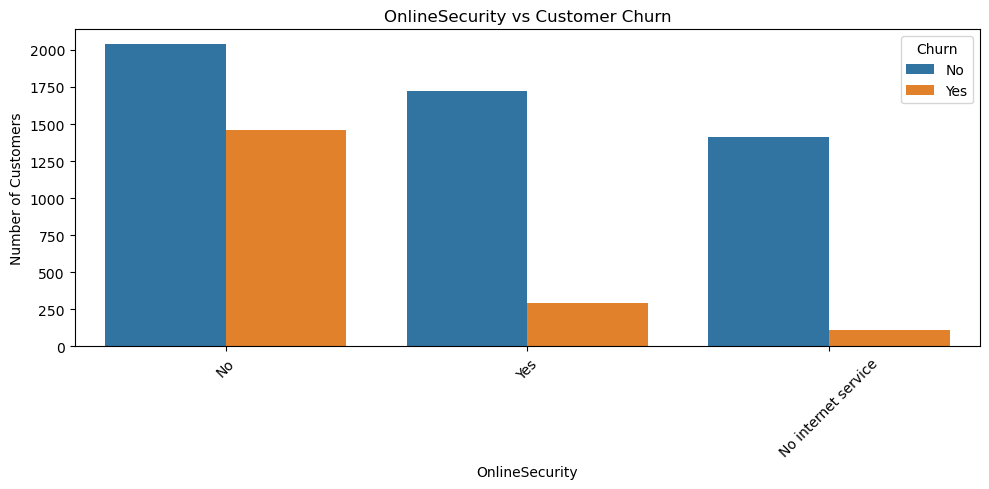

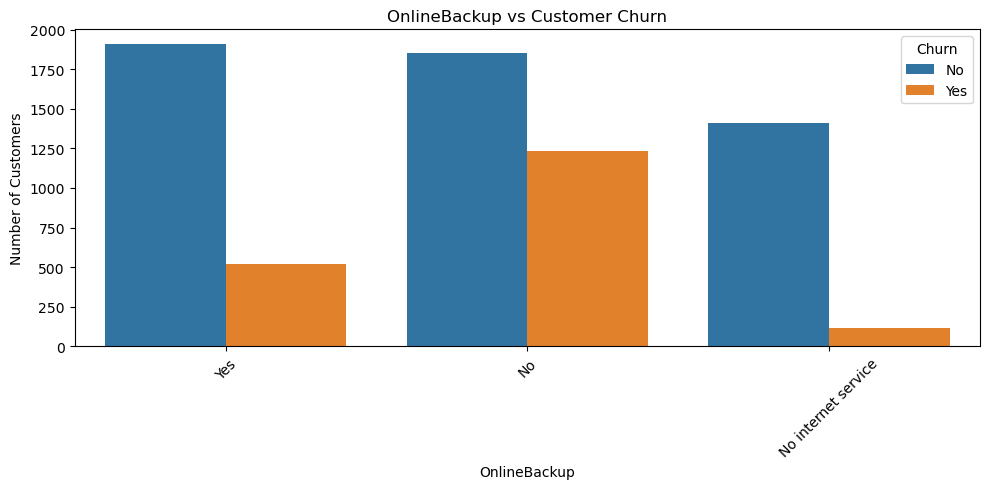

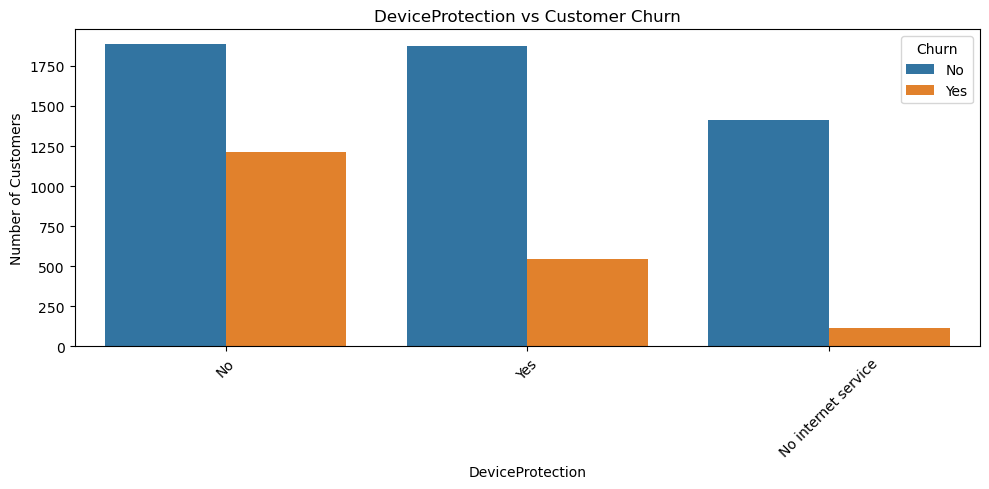

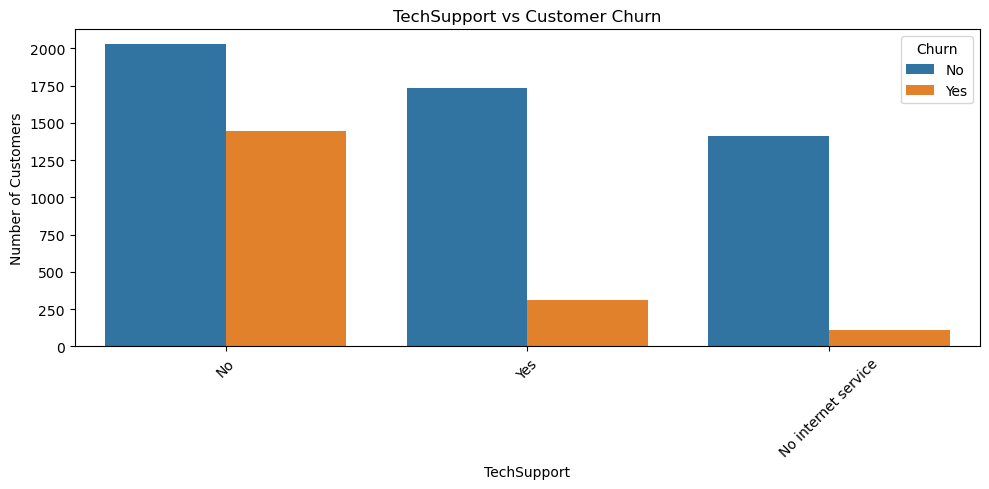

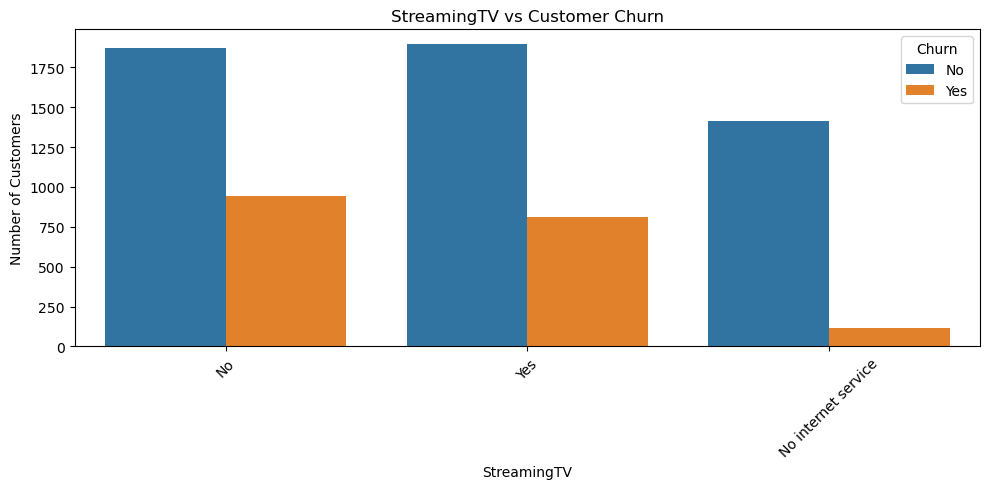

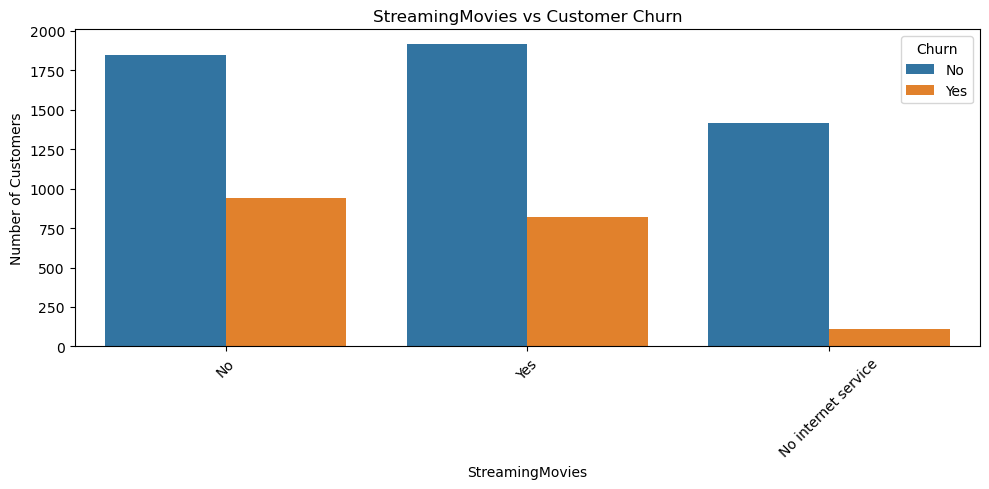

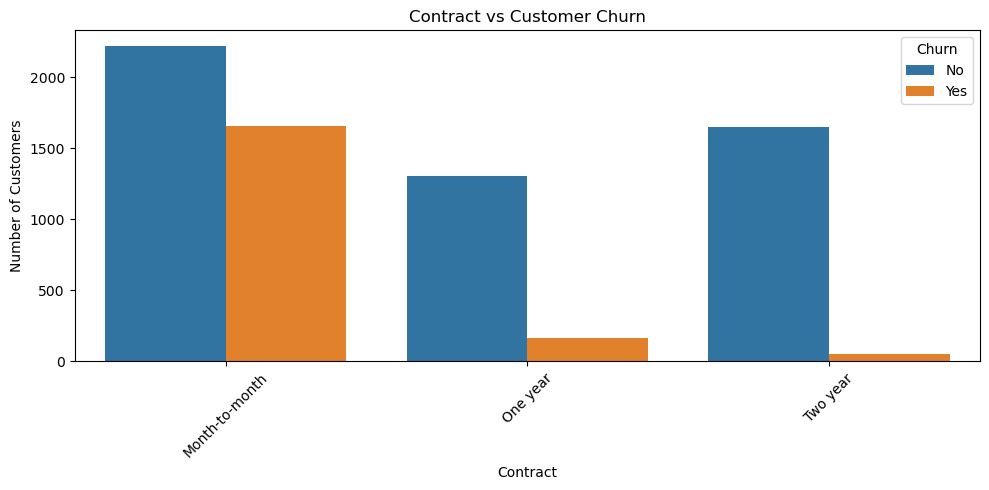

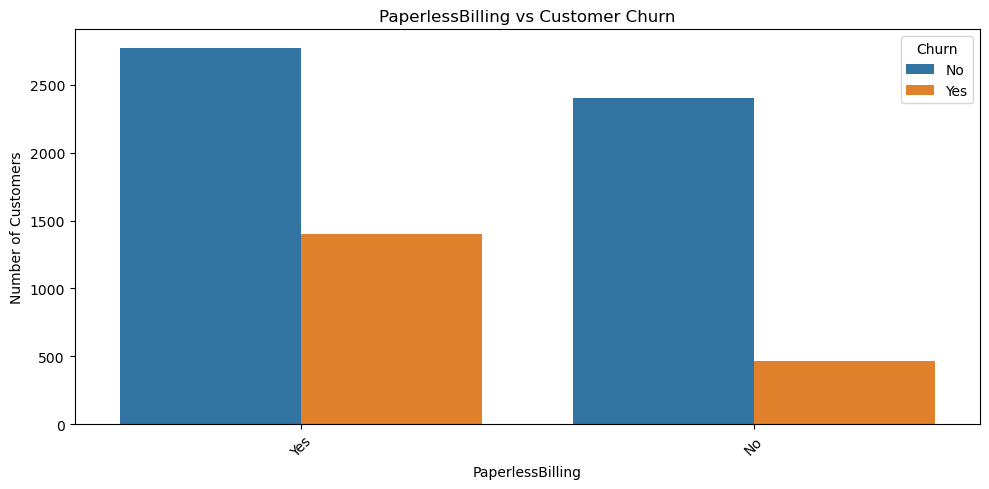

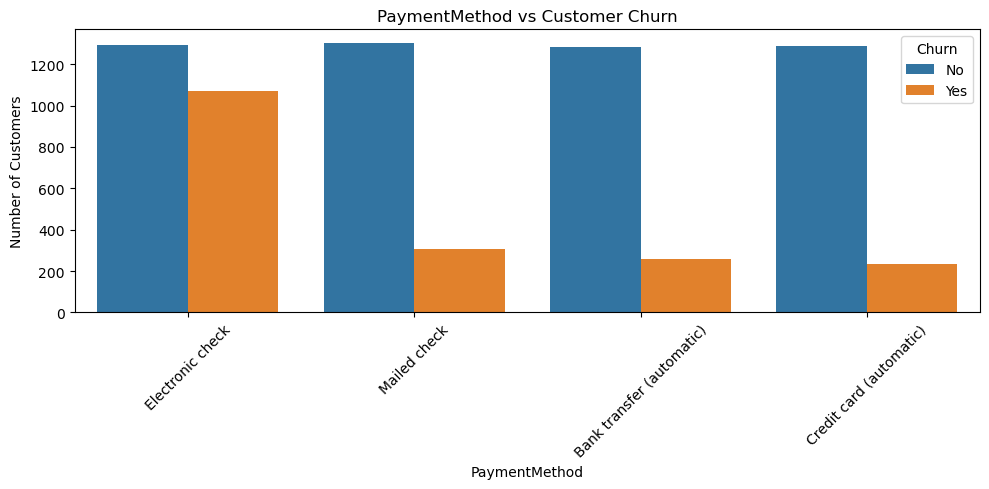

In [61]:
for feature in categorical_features:

    plt.figure(figsize=(10, 5))

    sns.countplot(
        data=df_clean,
        x=feature,
        hue='Churn'
    )

    plt.title(f"{feature} vs Customer Churn")
    plt.xlabel(feature)
    plt.ylabel("Number of Customers")
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()


###  Observations from Categorical Feature Analysis

After analyzing categorical features, I will record the important observations.

I will focus on:

1. Differences in churn across contract types.
2. Differences in churn across payment methods.
3. Relationship between internet service and churn.
4. Differences in churn across customer demographics.
5. Other service categories that show noticeable churn patterns.

These observations will help identify categorical features that may be useful for predicting customer churn.



###  Calculating the Correlation Matrix

I will use the corr() function to calculate the Pearson correlation coefficients between numerical features.

The correlation coefficient ranges from -1 to +1.

- +1 indicates a perfect positive linear relationship.
- -1 indicates a perfect negative linear relationship.
- 0 indicates no linear relationship.

This will help me identify numerical features that have strong relationships with each other.


In [62]:
correlation_matrix = df_clean[
    numerical_features
].corr()

correlation_matrix

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
SeniorCitizen,1.000000,0.016567,0.220173,0.103006
tenure,0.016567,1.000000,0.247900,0.826178
MonthlyCharges,0.220173,0.247900,1.000000,0.651174
TotalCharges,0.103006,0.826178,0.651174,1.000000



###  Correlation Heatmap

A correlation heatmap is a visualization that represents correlation coefficients using different colors.

It makes it easier to identify strong positive and negative relationships between numerical features.

I will create a heatmap to visualize the correlation matrix.


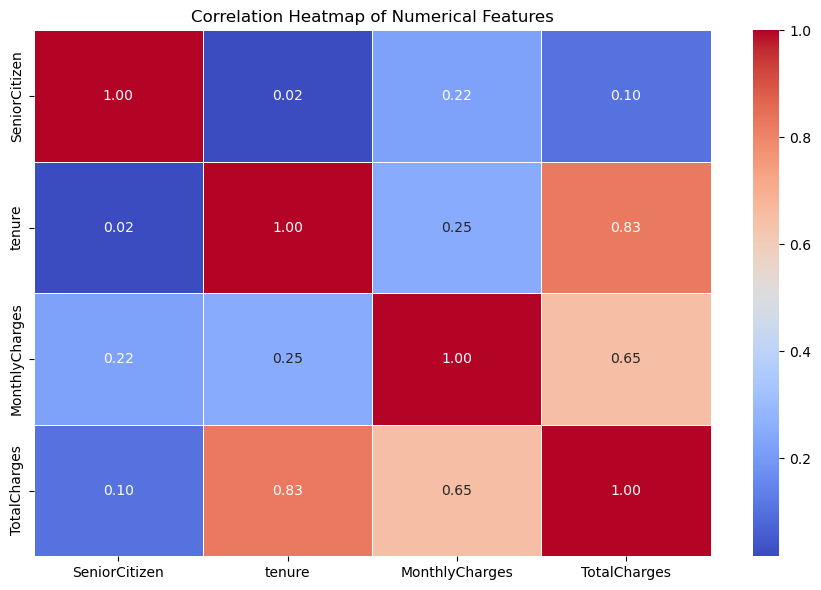

In [63]:
# Visualize correlation matrix

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")

plt.tight_layout()
plt.show()


###  Analyzing Correlation with the Target Variable

The Churn column is categorical and contains Yes and No values.

For numerical correlation analysis, I will temporarily convert these values into binary numerical representations.

- Yes = 1
- No = 0

I will calculate the correlation between numerical customer features and the encoded churn variable.

This will help me identify numerical features that show a linear association with customer churn.

The original Churn column will remain unchanged.


In [64]:
churn_encoded = df_clean['Churn'].map({
    'Yes': 1,
    'No': 0
})

# Create a temporary DataFrame for correlation analysis

correlation_data = df_clean[
    numerical_features
].copy()

correlation_data['Churn_Encoded'] = churn_encoded

# Calculate correlation with churn

churn_correlation = correlation_data.corr()[
    'Churn_Encoded'
].sort_values(ascending=False)

print("Correlation with Churn:\n")

print(churn_correlation)

Correlation with Churn:

Churn_Encoded     1.000000
MonthlyCharges    0.193356
SeniorCitizen     0.150889
TotalCharges     -0.198324
tenure           -0.352229
Name: Churn_Encoded, dtype: float64



###  Visualizing Feature Correlation with Churn

I will visualize the correlation between numerical customer features and the target variable.

A horizontal bar chart will make it easier to compare the direction and strength of these relationships.

This visualization will help identify numerical features that may contain useful information for churn prediction.


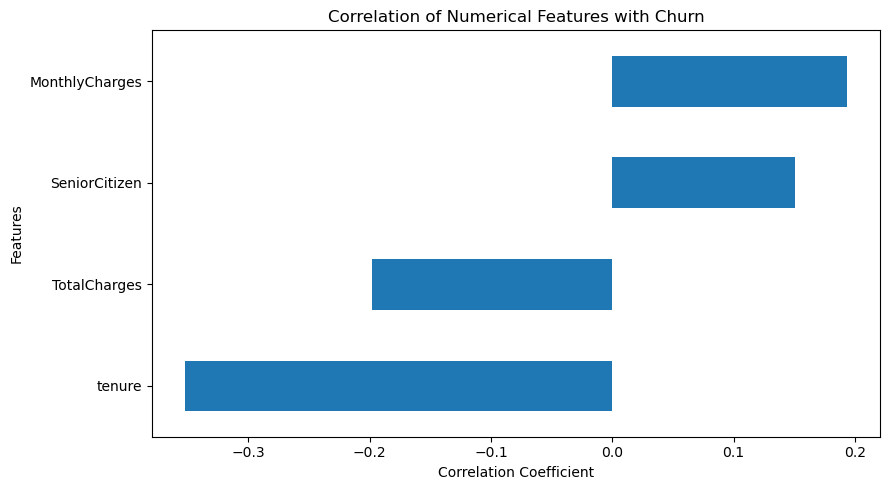

In [65]:
plt.figure(figsize=(9, 5))

churn_correlation.drop('Churn_Encoded').sort_values().plot(
    kind='barh'
)

plt.title("Correlation of Numerical Features with Churn")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Features")

plt.tight_layout()
plt.show()


###  Understanding Data Leakage

Data leakage occurs when information that would not legitimately be available during prediction is used during model training.

It can cause a Machine Learning model to achieve unusually high performance during training and evaluation but perform poorly on genuinely unseen data.

Possible sources of data leakage include:

1. Using information from the target variable as an input feature.
2. Performing preprocessing using the complete dataset before splitting.
3. Applying SMOTE before train-test splitting.
4. Using test data during hyperparameter tuning.
5. Including information that becomes available only after the customer has already left.

I will consider these risks while designing the preprocessing and model training workflow.


In [66]:
print("Available Dataset Columns:\n")

print(df_clean.columns.tolist())

print("\nTarget Variable:")
print("Churn")

print("\nTarget Column Included in Dataset:",
      'Churn' in df_clean.columns)

print("\nCustomer ID Included in Dataset:",
      'customerID' in df_clean.columns)

Available Dataset Columns:

['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Target Variable:
Churn

Target Column Included in Dataset: True

Customer ID Included in Dataset: False



### Checking Feature Availability at Prediction Time

A feature should only be used for prediction if its information would be available at the time the company wants to identify customers at risk of leaving.

For example:

- Customer tenure can be known before churn prediction.
- MonthlyCharges can be known before churn prediction.
- Contract information can be known before churn prediction.
- Churn is the target variable and cannot be used as an input feature.

TotalCharges requires consideration because it is related to customer tenure and accumulated charges.

For this project, I will assume that customer information is collected before the churn outcome being predicted.



###  EDA Findings and Business Insights

EDA helps us understand customer behavior and identify factors that may be associated with customer churn.

I will combine the observations from different visualizations and statistical analyses to identify meaningful patterns.

In [67]:
total_customers = len(df_clean)

churned_customers = (df_clean['Churn'] == 'Yes').sum()

retained_customers = (df_clean['Churn'] == 'No').sum()

overall_churn_rate = (
    churned_customers / total_customers
) * 100

overall_retention_rate = (
    retained_customers / total_customers
) * 100

eda_summary = pd.DataFrame({
    'Metric': [
        'Total Customers',
        'Churned Customers',
        'Retained Customers',
        'Churn Rate (%)',
        'Retention Rate (%)'
    ],
    'Value': [
        total_customers,
        churned_customers,
        retained_customers,
        round(overall_churn_rate, 2),
        round(overall_retention_rate, 2)
    ]
})

eda_summary

,Metric,Value
0,Total Customers,7043.00
1,Churned Customers,1869.00
2,Retained Customers,5174.00
3,Churn Rate (%),26.54
4,Retention Rate (%),73.46


In [68]:
# Analyze churn rates for important categorical features

important_categorical_features = [
    'Contract',
    'PaymentMethod',
    'InternetService',
    'OnlineSecurity',
    'TechSupport'
]

for feature in important_categorical_features:

    print(f"\nChurn Rate by {feature}:\n")

    churn_rate = (
        df_clean.groupby(feature)['Churn']
        .apply(lambda x: (x == 'Yes').mean() * 100)
        .sort_values(ascending=False)
    )

    print(churn_rate.round(2))


Churn Rate by Contract:

Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

Churn Rate by PaymentMethod:

PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn, dtype: float64

Churn Rate by InternetService:

InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn, dtype: float64

Churn Rate by OnlineSecurity:

OnlineSecurity
No                     41.77
Yes                    14.61
No internet service     7.40
Name: Churn, dtype: float64

Churn Rate by TechSupport:

TechSupport
No                     41.64
Yes                    15.17
No internet service     7.40
Name: Churn, dtype: float64



###  Comparing Customer Behavior by Churn Status

I will compare the average tenure, MonthlyCharges, and TotalCharges between customers who have left the company and customers who have stayed.

This comparison will help me understand differences in customer behavior across both groups.


In [69]:
customer_behavior_summary = df_clean.groupby('Churn')[
    ['tenure', 'MonthlyCharges', 'TotalCharges']
].mean().round(2)

customer_behavior_summary

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.57,61.27,2549.91
Yes,17.98,74.44,1531.80


Data Driven Business  INSIGHTS

In [71]:
print("=" * 55)

print(f"\n1. Overall Customer Churn Rate:")
print(f"{overall_churn_rate:.2f}% of customers have left the company.")

tenure_comparison = df_clean.groupby('Churn')['tenure'].mean()

print("\n2. Average Customer Tenure:")
print(tenure_comparison.round(2))

monthly_comparison = df_clean.groupby('Churn')['MonthlyCharges'].mean()

print("\n3. Average Monthly Charges:")
print(monthly_comparison.round(2))

contract_churn = (
    df_clean.groupby('Contract')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100)
)

print("\n4. Contract Type with Highest Churn Rate:")
print(contract_churn.idxmax())
print(f"Churn Rate: {contract_churn.max():.2f}%")

payment_churn = (
    df_clean.groupby('PaymentMethod')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100)
)

print("\n5. Payment Method with Highest Churn Rate:")
print(payment_churn.idxmax())
print(f"Churn Rate: {payment_churn.max():.2f}%")

internet_churn = (
    df_clean.groupby('InternetService')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100)
)

print("\n6. Internet Service with Highest Churn Rate:")
print(internet_churn.idxmax())
print(f"Churn Rate: {internet_churn.max():.2f}%")


1. Overall Customer Churn Rate:
26.54% of customers have left the company.

2. Average Customer Tenure:
Churn
No     37.57
Yes    17.98
Name: tenure, dtype: float64

3. Average Monthly Charges:
Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64

4. Contract Type with Highest Churn Rate:
Month-to-month
Churn Rate: 42.71%

5. Payment Method with Highest Churn Rate:
Electronic check
Churn Rate: 45.29%

6. Internet Service with Highest Churn Rate:
Fiber optic
Churn Rate: 41.89%


In [72]:
business_insights = pd.DataFrame({
    'Analysis Area': [
        'Overall Churn',
        'Customer Tenure',
        'Monthly Charges',
        'Contract Type',
        'Payment Method',
        'Internet Service'
    ],
    'Observation': [
        f"Overall churn rate is {overall_churn_rate:.2f}%.",
        f"Average tenure of churned customers is {tenure_comparison['Yes']:.2f} months, compared with {tenure_comparison['No']:.2f} months for retained customers.",
        f"Average monthly charges are {monthly_comparison['Yes']:.2f} for churned customers and {monthly_comparison['No']:.2f} for retained customers.",
        f"{contract_churn.idxmax()} has the highest observed churn rate of {contract_churn.max():.2f}%.",
        f"{payment_churn.idxmax()} has the highest observed churn rate of {payment_churn.max():.2f}%.",
        f"{internet_churn.idxmax()} has the highest observed churn rate of {internet_churn.max():.2f}%."
    ]
})

business_insights

,Analysis Area,Observation
0,Overall Churn,Overall churn rate is 26.54%.
1,Customer Tenure,Average tenure of churned customers is 17.98 m...
2,Monthly Charges,Average monthly charges are 74.44 for churned ...
3,Contract Type,Month-to-month has the highest observed churn ...
4,Payment Method,Electronic check has the highest observed chur...
5,Internet Service,Fiber optic has the highest observed churn rat...



###  EDA Conclusion

Exploratory Data Analysis helped me understand the customer churn dataset and identify different patterns in customer behavior.

I analyzed numerical features, categorical features, churn distribution, and relationships between numerical variables.

The analysis provided useful information about customer tenure, monthly charges, contract types, payment methods, and service subscriptions.

These findings will help me select relevant features and prepare the dataset for Machine Learning.

EDA also helped me understand the importance of handling class imbalance, avoiding data leakage, and checking relationships between features before model development.



# Feature Engineering and Data Preprocessing

In [73]:
X = df_clean.drop(columns=['Churn'])

y = df_clean['Churn']

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

Input Features Shape: (7043, 19)
Target Variable Shape: (7043,)



###  Encoding the Target Variable

The Churn target variable currently contains two categorical values: Yes and No.

Most Machine Learning classification algorithms require the target labels to be represented numerically.

Therefore, I will convert the target variable into binary values.

- Yes = 1
- No = 0

This represents a binary classification problem where the model predicts whether a customer will leave the company.


In [74]:
y = y.map({
    'No': 0,
    'Yes': 1
})

print("Target Variable Values:")
print(y.value_counts())

print("\nTarget Data Type:", y.dtype)

Target Variable Values:
Churn
0    5174
1    1869
Name: count, dtype: int64

Target Data Type: int64


In [75]:
# Verifying  target variable

print("Unique Target Values:", y.unique())

print("Missing Target Values:", y.isnull().sum())

print("\nTarget Variable Distribution:")
print(y.value_counts())

Unique Target Values: [0 1]
Missing Target Values: 0

Target Variable Distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


### Identifying Numerical and Categorical Features

In [76]:
X = X.copy()

# Treat SeniorCitizen as a categorical feature

X['SeniorCitizen'] = X['SeniorCitizen'].astype('object')

# Identifying  numerical and categorical features

numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nTotal Numerical Features:", len(numerical_features))
print("Total Categorical Features:", len(categorical_features))

Numerical Features:
['tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Total Numerical Features: 3
Total Categorical Features: 16


In [77]:
print("Numerical Feature Summary:\n")

X[numerical_features].describe()

Numerical Feature Summary:



,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000



# Splitting the Dataset

Before training Machine Learning models, I will divide the dataset into three separate parts.

**Training Set (70%):**
Used to train Machine Learning models and learn patterns from customer information.

**Validation Set (15%):**
Used to compare models, tune parameters, and make development decisions.

**Testing Set (15%):**
Used for final evaluation to understand how well the selected model performs on unseen customer data.

I will use the train_test_split() function from Scikit-learn.

I will also use stratify to maintain approximately the same churn class distribution in all three datasets.

A fixed random_state will make the data splitting reproducible.


In [78]:
from sklearn.model_selection import train_test_split

In [79]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Temporary Features:", X_temp.shape)

Training Features: (4930, 19)
Temporary Features: (2113, 19)


In [80]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training Set:", X_train.shape)
print("Validation Set:", X_val.shape)
print("Testing Set:", X_test.shape)

Training Set: (4930, 19)
Validation Set: (1056, 19)
Testing Set: (1057, 19)


In [81]:
# Checking  churn distribution in each dataset for Better Result

print("Training Set Distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nValidation Set Distribution:")
print(y_val.value_counts(normalize=True).round(3))

print("\nTesting Set Distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training Set Distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

Validation Set Distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

Testing Set Distribution:
Churn
0    0.734
1    0.266
Name: proportion, dtype: float64



###  Dataset Splitting Summary
I will create a summary of the training, validation, and testing datasets.

This will help me verify the number of records assigned to each set before starting preprocessing and model development.


In [82]:
split_summary = pd.DataFrame({
    'Dataset': ['Training', 'Validation', 'Testing'],
    'Number of Records': [
        len(X_train),
        len(X_val),
        len(X_test)
    ],
    'Percentage': [
        len(X_train) / len(X) * 100,
        len(X_val) / len(X) * 100,
        len(X_test) / len(X) * 100
    ]
})

split_summary['Percentage'] = split_summary['Percentage'].round(2)

split_summary

,Dataset,Number of Records,Percentage
0,Training,4930,70.00
1,Validation,1056,14.99
2,Testing,1057,15.01



###  Understanding Label Encoding

Label Encoding converts categorical labels into numerical values.

For example:

- Yes = 1
- No = 0

It is useful for binary categorical variables and target labels.

However, assigning numerical values to nominal categories may introduce an artificial ordering.

Therefore, I will avoid applying ordinary Label Encoding to unordered input categories such as Contract and PaymentMethod.

The target variable Churn has already been converted into binary values in the previous section.



###  Understanding One-Hot Encoding

One-Hot Encoding converts each category into a separate binary column.

For example, the Contract column contains three categories:

- Month-to-month
- One year
- Two year

After One-Hot Encoding, these categories will be represented using separate columns containing 0 and 1.

I will use OneHotEncoder from Scikit-learn to transform categorical features.

I will use handle_unknown='ignore' so that the preprocessing pipeline can handle previously unseen categories in new customer records.



###  Difference Between Standardization and Normalization

Standardization and normalization are two techniques used to transform numerical features.

**Standardization:**

Standardization transforms data to have approximately zero mean and unit standard deviation.

It is performed using StandardScaler.

**Normalization:**

Min-Max normalization transforms values into a specified range, commonly between 0 and 1.

It is performed using MinMaxScaler.

In this project, I will use StandardScaler as the primary scaling technique because it is suitable for models such as Logistic Regression and Support Vector Machines.

I will not apply both scaling techniques to the same features simultaneously without a specific reason.


In [84]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline


###  Creating Numerical Preprocessing Pipeline

In [85]:
numerical_transformer = Pipeline(
    steps=[
        ('scaler', StandardScaler())
    ]
)

print("Numerical preprocessing pipeline created successfully!")

Numerical preprocessing pipeline created successfully!


In [86]:
categorical_transformer = Pipeline(
    steps=[
        (
            'encoder',
            OneHotEncoder(
                handle_unknown='ignore',
                drop='first'
            )
        )
    ]
)

print("Categorical preprocessing pipeline created successfully!")

Categorical preprocessing pipeline created successfully!



###  Combining Preprocessing Transformations

Numerical and categorical features require different preprocessing techniques.

Therefore, I will combine both preprocessing pipelines using ColumnTransformer.

- Numerical features will be processed using StandardScaler.
- Categorical features will be processed using OneHotEncoder.

This allows different transformations to be applied to the appropriate columns within one preprocessing object.


In [87]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Combined preprocessing transformer created successfully!")

Combined preprocessing transformer created successfully!



# Fitting the Preprocessing Transformer

Now I will fit the preprocessing transformer using only the training dataset.

During this step:

- StandardScaler will learn the mean and standard deviation of numerical training features.
- OneHotEncoder will learn the categories available in categorical training features.

The validation and testing datasets will not be used to learn these transformations.

This prevents information from the validation and testing datasets from leaking into the training process.


In [88]:
preprocessor.fit(X_train)

print("Preprocessing transformer fitted on training data!")

Preprocessing transformer fitted on training data!


###  Transforming Training Data

In [89]:
X_train_processed = preprocessor.transform(X_train)

print("Training data transformed successfully!")
print("Processed Training Shape:", X_train_processed.shape)

Training data transformed successfully!
Processed Training Shape: (4930, 30)


In [90]:
X_val_processed = preprocessor.transform(X_val)

X_test_processed = preprocessor.transform(X_test)

print("Validation Shape:", X_val_processed.shape)
print("Testing Shape:", X_test_processed.shape)

Validation Shape: (1056, 30)
Testing Shape: (1057, 30)


In [91]:
processed_feature_names = preprocessor.get_feature_names_out()

print("Total Processed Features:", len(processed_feature_names))

print("\nFirst 20 Processed Feature Names:")

print(processed_feature_names[:20])

Total Processed Features: 30

First 20 Processed Feature Names:
['num__tenure' 'num__MonthlyCharges' 'num__TotalCharges'
 'cat__gender_Male' 'cat__SeniorCitizen_1' 'cat__Partner_Yes'
 'cat__Dependents_Yes' 'cat__PhoneService_Yes'
 'cat__MultipleLines_No phone service' 'cat__MultipleLines_Yes'
 'cat__InternetService_Fiber optic' 'cat__InternetService_No'
 'cat__OnlineSecurity_No internet service' 'cat__OnlineSecurity_Yes'
 'cat__OnlineBackup_No internet service' 'cat__OnlineBackup_Yes'
 'cat__DeviceProtection_No internet service' 'cat__DeviceProtection_Yes'
 'cat__TechSupport_No internet service' 'cat__TechSupport_Yes']


In [92]:
# Converting  processed training data into DataFrame

X_train_processed_df = pd.DataFrame(
    X_train_processed.toarray()
    if hasattr(X_train_processed, 'toarray')
    else X_train_processed,
    columns=processed_feature_names,
    index=X_train.index
)

X_train_processed_df.head()

,num__tenure,num__MonthlyCharges,num__TotalCharges,cat__gender_Male,cat__SeniorCitizen_1,cat__Partner_Yes,cat__Dependents_Yes,cat__PhoneService_Yes,cat__MultipleLines_No phone service,cat__MultipleLines_Yes,...,cat__StreamingTV_No internet service,cat__StreamingTV_Yes,cat__StreamingMovies_No internet service,cat__StreamingMovies_Yes,cat__Contract_One year,cat__Contract_Two year,cat__PaperlessBilling_Yes,cat__PaymentMethod_Credit card (automatic),cat__PaymentMethod_Electronic check,cat__PaymentMethod_Mailed check
5557,-1.114728,0.504286,-0.836504,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2270,-1.195884,0.724189,-0.907742,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
6930,-1.195884,0.337292,-0.909574,0.0,0.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
2257,1.117066,0.515860,1.110332,0.0,0.0,0.0,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
898,-0.830682,1.122660,-0.515129,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0


In [93]:
scaled_columns = [
    f'num__{feature}'
    for feature in numerical_features
]

scaling_summary = pd.DataFrame({
    'Mean': X_train_processed_df[scaled_columns].mean(),
    'Standard Deviation': X_train_processed_df[scaled_columns].std()
})

scaling_summary.round(3)

,Mean,Standard Deviation
num__tenure,-0.0,1.0
num__MonthlyCharges,0.0,1.0
num__TotalCharges,-0.0,1.0



## Outlier Analysis

Outliers are values that are unusually high or low compared to most other values.

In this project, we will inspect numerical features such as:
- Tenure
- Monthly Charges
- Total Charges

We will use the Interquartile Range (IQR) method to identify possible outliers.

Important: We will not automatically remove outliers. Some customers may legitimately have high monthly or total charges. Removing valid customer records could reduce useful information.


In [94]:

outlier_summary = []

for column in numerical_features:

    Q1 = X_train[column].quantile(0.25)
    Q3 = X_train[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outlier_count = (
        (X_train[column] < lower_limit) |
        (X_train[column] > upper_limit)
    ).sum()

    outlier_summary.append({
        'Feature': column,
        'Lower Limit': lower_limit,
        'Upper Limit': upper_limit,
        'Outlier Count': outlier_count
    })

outlier_summary_df = pd.DataFrame(outlier_summary)

outlier_summary_df.round(2)


,Feature,Lower Limit,Upper Limit,Outlier Count
0,tenure,-61.50,126.50,0
1,MonthlyCharges,-46.32,171.88,0
2,TotalCharges,-4794.71,9048.04,0



### Visualizing Outliers with Boxplots

Boxplots help us visually identify values that fall outside the usual range.



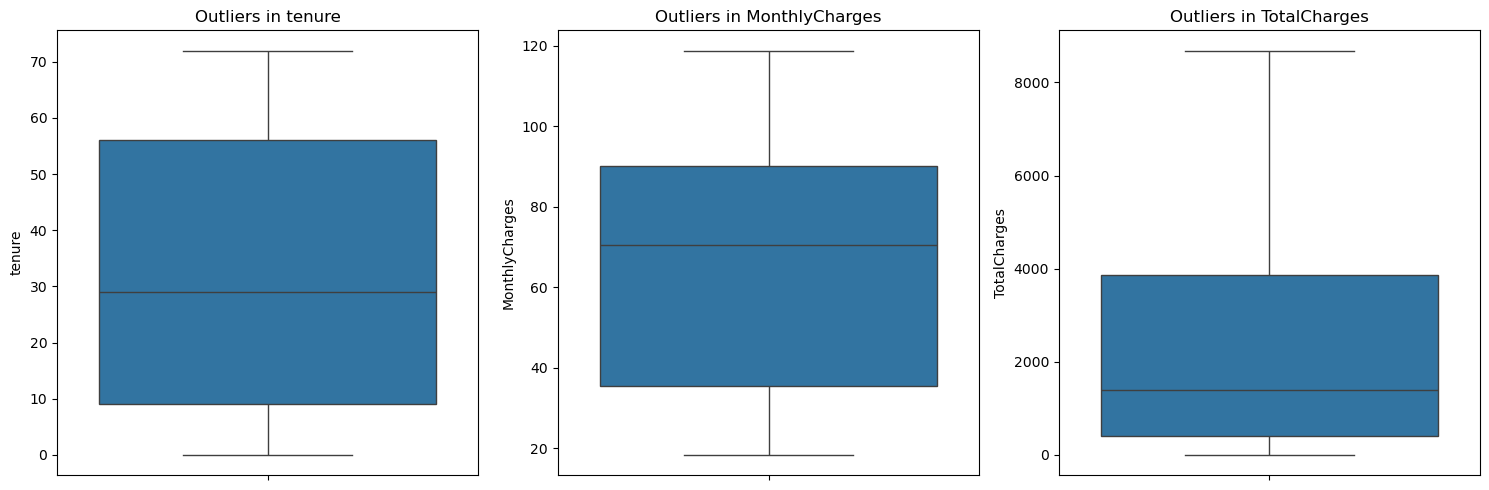

In [95]:

plt.figure(figsize=(15, 5))

for index, column in enumerate(numerical_features, 1):

    plt.subplot(1, len(numerical_features), index)

    sns.boxplot(y=X_train[column])

    plt.title(f'Outliers in {column}')
    plt.ylabel(column)

plt.tight_layout()
plt.show()



### Outlier Handling Decision

After inspecting the outlier counts and boxplots, we will not automatically remove extreme values.

Reasons:
1. High Total Charges may represent customers who have used the service for a long time.
2. High Monthly Charges may represent customers using premium services.
3. Removing valid customer records may cause information loss.

Therefore, we will retain the original customer records and continue with the existing preprocessing pipeline.

This decision can be reviewed later if we discover incorrect or invalid values.


In [96]:

print("Missing values in training data:")
print(X_train.isnull().sum().sum())

print("\nMissing values in validation data:")
print(X_val.isnull().sum().sum())

print("\nMissing values in testing data:")
print(X_test.isnull().sum().sum())


Missing values in training data:
0

Missing values in validation data:
0

Missing values in testing data:
0


In [97]:

print("Original Dataset Shapes")
print("-----------------------")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nProcessed Dataset Shapes")
print("------------------------")
print("Training:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Testing:", X_test_processed.shape)


Original Dataset Shapes
-----------------------
Training: (4930, 19)
Validation: (1056, 19)
Testing: (1057, 19)

Processed Dataset Shapes
------------------------
Training: (4930, 30)
Validation: (1056, 30)
Testing: (1057, 30)


In [98]:

print(
    "Training and validation feature dimensions match:",
    X_train_processed.shape[1] == X_val_processed.shape[1]
)

print(
    "Training and testing feature dimensions match:",
    X_train_processed.shape[1] == X_test_processed.shape[1]
)

print("\nNumber of processed feature names:", len(processed_feature_names))

# Check for infinite or invalid numerical values
print(
    "\nTraining data contains only finite values:",
    np.isfinite(X_train_processed.toarray()
                if hasattr(X_train_processed, "toarray")
                else X_train_processed).all()
)


Training and validation feature dimensions match: True
Training and testing feature dimensions match: True

Number of processed feature names: 30

Training data contains only finite values: True



# Summary — Feature Engineering and Preprocessing

In this part, we completed the following tasks:

1. Separated input features and the target variable.
2. Converted the target variable into numerical values.
3. Identified numerical and categorical features.
4. Split the dataset into training, validation, and testing sets.
5. Applied One-Hot Encoding to categorical features.
6. Applied Standard Scaling to numerical features.
7. Used a preprocessing pipeline.
8. Identified possible numerical outliers.
9. Verified missing values and processed feature dimensions.

The preprocessing transformer was fitted using only the training data. Validation and test data were transformed using the same fitted transformer.

We are now ready to begin machine learning model development.



#  Machine Learning Model Development

Machine Learning algorithms learn patterns from historical customer data and use those patterns to predict whether a customer is likely to leave the company.

In this project, I am going to train and compare five classification algorithms:

1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Support Vector Machine (SVM)
5. Gradient Boosting

I will use the same training and validation datasets for all models.

Evaluate the models using:
- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC

The test dataset will remain untouched until final model evaluation.


In [100]:

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)


from sklearn.pipeline import Pipeline
from sklearn.base import clone

import time



### Creating Machine Learning Pipelines

Each pipeline contains two main steps:

1. Preprocessing: handles numerical scaling and categorical encoding.
2. Classification: learns patterns and predicts customer churn.

This approach is important because preprocessing will be fitted only on the training data whenever a model is trained. It also helps prevent data leakage during future cross-validation.


In [103]:

models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    'Support Vector Machine': SVC(
        probability=True,
        random_state=42
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        random_state=42
    )
}


model_pipelines = {}

for model_name, model in models.items():

    model_pipeline = Pipeline(steps=[
        ('preprocessor', clone(preprocessor)),
        ('classifier', model)
    ])

    model_pipelines[model_name] = model_pipeline

print("Machine learning pipelines created successfully.")

print("\nModels included:")
for model_name in model_pipelines:
    print("-", model_name)


Machine learning pipelines created successfully.

Models included:
- Logistic Regression
- Decision Tree
- Random Forest
- Support Vector Machine
- Gradient Boosting



### Training Machine Learning Models

In [104]:

training_times = {}

for model_name, model_pipeline in model_pipelines.items():

    print(f"\nTraining {model_name}...")

    start_time = time.time()

    model_pipeline.fit(X_train, y_train)

    end_time = time.time()

    training_times[model_name] = end_time - start_time

    print(f"{model_name} training completed.")
    print(f"Training time: {training_times[model_name]:.2f} seconds")



Training Logistic Regression...
Logistic Regression training completed.
Training time: 0.44 seconds

Training Decision Tree...
Decision Tree training completed.
Training time: 0.05 seconds

Training Random Forest...
Random Forest training completed.
Training time: 0.14 seconds

Training Support Vector Machine...
Support Vector Machine training completed.
Training time: 2.84 seconds

Training Gradient Boosting...
Gradient Boosting training completed.
Training time: 0.51 seconds



### Making Predictions on Validation Data

- Class prediction: 0 means the customer will not churn, and 1 means the customer will churn.
- Probability prediction: estimates how likely the customer is to churn.

I am going to use the probability of class 1 to calculate ROC-AUC.


In [105]:

validation_predictions = {}
validation_probabilities = {}

for model_name, model_pipeline in model_pipelines.items():

    y_pred = model_pipeline.predict(X_val)

    y_probability = model_pipeline.predict_proba(X_val)[:, 1]

    validation_predictions[model_name] = y_pred
    validation_probabilities[model_name] = y_probability

    print(f"{model_name} predictions generated.")


Logistic Regression predictions generated.
Decision Tree predictions generated.
Random Forest predictions generated.
Support Vector Machine predictions generated.
Gradient Boosting predictions generated.



### Model Evaluation

1. Accuracy: percentage of total predictions that are correct.
2. Precision: among customers predicted to churn, how many actually churned?
3. Recall: among customers who actually churned, how many did the model identify?
4. F1-score: balance between precision and recall.
5. ROC-AUC: measures how well the model separates churn and non-churn customers across different classification thresholds.



In [106]:

model_results = []

for model_name in model_pipelines:

    y_pred = validation_predictions[model_name]
    y_probability = validation_probabilities[model_name]

    results = {
        'Model': model_name,
        'Accuracy': accuracy_score(y_val, y_pred),
        'Precision': precision_score(y_val, y_pred, zero_division=0),
        'Recall': recall_score(y_val, y_pred, zero_division=0),
        'F1 Score': f1_score(y_val, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_val, y_probability),
        'Training Time (seconds)': training_times[model_name]
    }

    model_results.append(results)

model_comparison = pd.DataFrame(model_results)

model_comparison = model_comparison.sort_values(
    by='ROC-AUC',
    ascending=False
).reset_index(drop=True)

model_comparison.round(4)


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (seconds)
0,Gradient Boosting,0.8011,0.6549,0.5286,0.5850,0.8479,0.5144
1,Logistic Regression,0.8087,0.6523,0.5964,0.6231,0.8454,0.4407
2,Random Forest,0.7812,0.6043,0.5071,0.5515,0.8242,0.1381
3,Support Vector Machine,0.8030,0.6636,0.5214,0.5840,0.8050,2.8418
4,Decision Tree,0.7301,0.4910,0.4893,0.4902,0.6528,0.0524



### Comparing Model Performance Visually

A comparison chart makes it easier to understand how different algorithms perform.

compare accuracy, precision, recall, F1-score, and ROC-AUC.


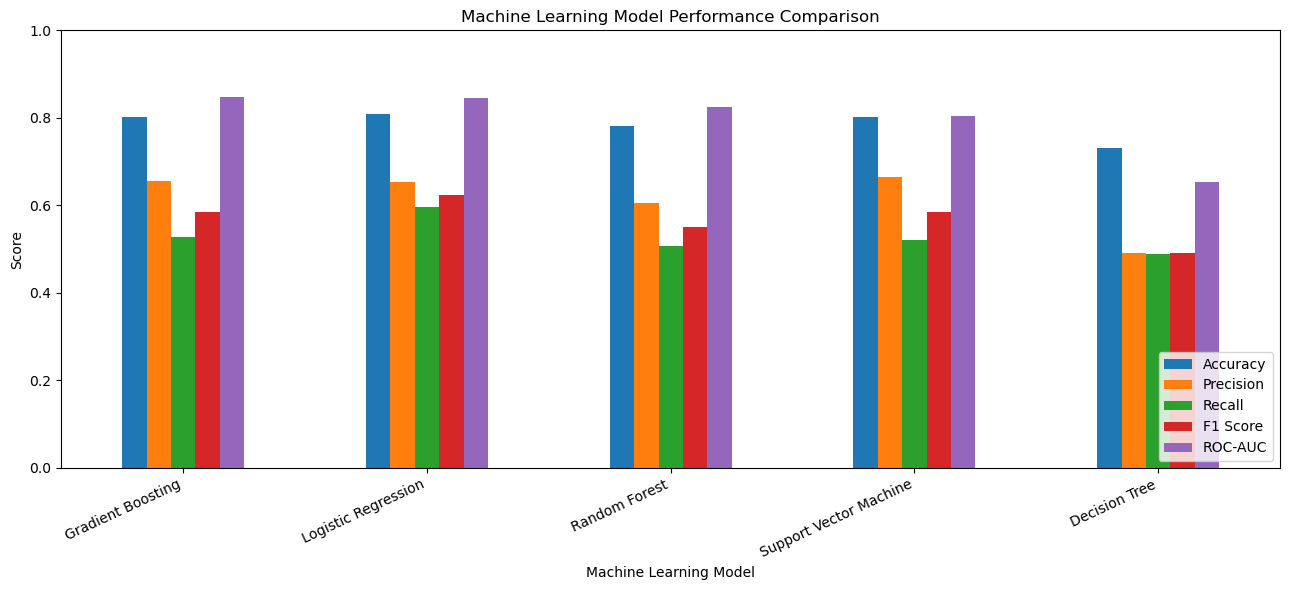

In [107]:

metrics_to_plot = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1 Score',
    'ROC-AUC'
]

model_comparison.set_index('Model')[metrics_to_plot].plot(
    kind='bar',
    figsize=(13, 6)
)

plt.title('Machine Learning Model Performance Comparison')
plt.ylabel('Score')
plt.xlabel('Machine Learning Model')
plt.ylim(0, 1)
plt.xticks(rotation=25, ha='right')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()



### Identifying the Best Baseline Model

This is only our initial baseline selection. We will not consider it the final model yet.

In later steps, I will examine class imbalance, tune model parameters, and compare the models again using additional evaluation methods.


In [108]:

best_model_name = model_comparison.iloc[0]['Model']

best_model = model_pipelines[best_model_name]

print("Best baseline model:", best_model_name)

print("\nValidation performance:")
print(
    model_comparison.iloc[0].to_string()
)


Best baseline model: Gradient Boosting

Validation performance:
Model                      Gradient Boosting
Accuracy                            0.801136
Precision                           0.654867
Recall                              0.528571
F1 Score                             0.58498
ROC-AUC                             0.847897
Training Time (seconds)             0.514366



##  Confusion Matrix Analysis

A confusion matrix helps us understand the types of mistakes made by a classification model.

It contains four values:

1. True Positive (TP): Correctly predicted churn customers.
2. True Negative (TN): Correctly predicted non-churn customers.
3. False Positive (FP): Non-churn customers incorrectly predicted as churn.
4. False Negative (FN): Churn customers incorrectly predicted as non-churn.

In customer churn prediction, False Negatives are important because the company may lose customers without identifying them as potential churners.


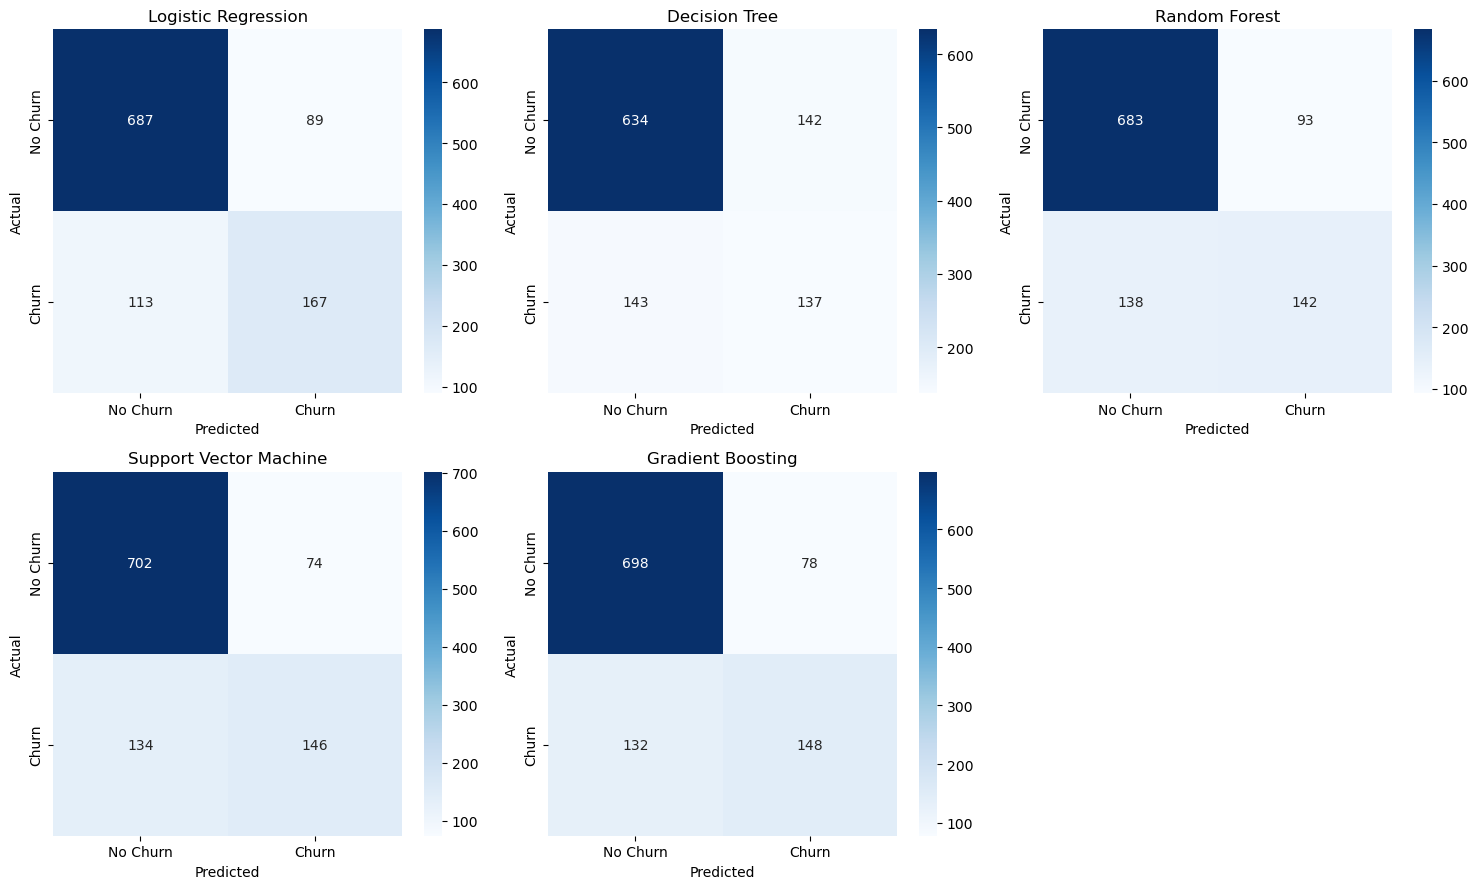

In [109]:

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

axes = axes.flatten()

for index, model_name in enumerate(model_pipelines):

    cm = confusion_matrix(
        y_val,
        validation_predictions[model_name]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=axes[index],
        xticklabels=['No Churn', 'Churn'],
        yticklabels=['No Churn', 'Churn']
    )

    axes[index].set_title(model_name)
    axes[index].set_xlabel('Predicted')
    axes[index].set_ylabel('Actual')

# Remove the unused sixth subplot
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()



### Detailed Error Analysis of Gradient Boosting

Gradient Boosting was selected as our best baseline model based on validation ROC-AUC.

Now I will examine its confusion matrix separately to understand:

- How many customers were correctly identified as churners?
- How many churn customers were missed?
- How many non-churn customers were incorrectly classified as churners?

This will help us understand where the model needs improvement.


In [110]:

gb_predictions = validation_predictions['Gradient Boosting']

gb_cm = confusion_matrix(y_val, gb_predictions)

TN, FP, FN, TP = gb_cm.ravel()

print("Gradient Boosting Confusion Matrix Analysis")
print("-------------------------------------------")

print("True Negatives:", TN)
print("False Positives:", FP)
print("False Negatives:", FN)
print("True Positives:", TP)


Gradient Boosting Confusion Matrix Analysis
-------------------------------------------
True Negatives: 698
False Positives: 78
False Negatives: 132
True Positives: 148


In [111]:

print("Gradient Boosting Classification Report")
print("----------------------------------------")

print(
    classification_report(
        y_val,
        gb_predictions,
        target_names=['No Churn', 'Churn'],
        zero_division=0
    )
)


Gradient Boosting Classification Report
----------------------------------------
              precision    recall  f1-score   support

    No Churn       0.84      0.90      0.87       776
       Churn       0.65      0.53      0.58       280

    accuracy                           0.80      1056
   macro avg       0.75      0.71      0.73      1056
weighted avg       0.79      0.80      0.79      1056



In [112]:

# Checking  class distribution in the training dataset

class_counts = y_train.value_counts().sort_index()

print("Training Dataset Class Distribution")
print("-----------------------------------")

print("No Churn (0):", class_counts[0])
print("Churn (1):", class_counts[1])

print("\nClass percentages:")

class_percentages = (
    y_train.value_counts(normalize=True).sort_index() * 100
)

print(class_percentages.round(2))


Training Dataset Class Distribution
-----------------------------------
No Churn (0): 3622
Churn (1): 1308

Class percentages:
Churn
0    73.47
1    26.53
Name: proportion, dtype: float64



### Visualizing Class Imbalance


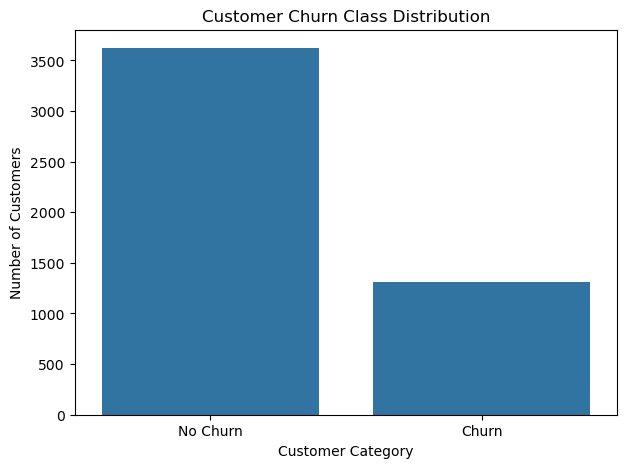

In [113]:
plt.figure(figsize=(7, 5))

sns.countplot(
    x=y_train.map({0: 'No Churn', 1: 'Churn'})
)

plt.title('Customer Churn Class Distribution')
plt.xlabel('Customer Category')
plt.ylabel('Number of Customers')

plt.show()



### Why Accuracy Alone Is Not Enough

In an imbalanced dataset, accuracy does not always represent the actual ability of a model to identify the minority class.

For example, if most customers do not churn, a model could achieve high accuracy by predicting No Churn for most customers.

However, such a model may fail to identify customers who are actually leaving.

Therefore, I will also focus on:

- Recall: to identify more actual churn customers.
- Precision: to avoid unnecessary retention campaigns.
- F1-score: to balance precision and recall.
- ROC-AUC: to evaluate class separation.

I will compare these metrics before and after handling class imbalance.


In [114]:

majority_count = class_counts.max()
minority_count = class_counts.min()

imbalance_ratio = majority_count / minority_count

print("Majority Class Count:", majority_count)
print("Minority Class Count:", minority_count)

print("Imbalance Ratio:", round(imbalance_ratio, 2))

if imbalance_ratio > 1.5:
    print("\nThe training dataset shows class imbalance.")
else:
    print("\nThe class distribution is relatively balanced.")


Majority Class Count: 3622
Minority Class Count: 1308
Imbalance Ratio: 2.77

The training dataset shows class imbalance.




###  SMOTE Technique

SMOTE stands for Synthetic Minority Over-sampling Technique.

It is used to handle class imbalance by generating synthetic examples of the minority class.

In our project:
- No Churn is the majority class.
- Churn is the minority class.

SMOTE generates new synthetic Churn examples using existing minority-class examples.

Important:
- SMOTE will be applied only to the training data.
- Validation and test data will remain unchanged.
- We will use a pipeline to prevent data leakage.

I will compare SMOTE results with our baseline and class-weighted models.


In [115]:

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

print("SMOTE imported successfully.")


SMOTE imported successfully.



### Creating SMOTE Model Pipelines


In [116]:

smote_model_pipelines = {}

for model_name, model in models.items():

    smote_pipeline = ImbPipeline(steps=[
        ('preprocessor', clone(preprocessor)),
        ('smote', SMOTE(random_state=42)),
        ('classifier', clone(model))
    ])

    smote_model_pipelines[model_name] = smote_pipeline

print("SMOTE pipelines created successfully.")

for model_name in smote_model_pipelines:
    print("-", model_name)


SMOTE pipelines created successfully.
- Logistic Regression
- Decision Tree
- Random Forest
- Support Vector Machine
- Gradient Boosting



### Training Models with SMOTE

In [117]:

smote_training_times = {}

for model_name, smote_pipeline in smote_model_pipelines.items():

    print(f"\nTraining {model_name} with SMOTE...")

    start_time = time.time()

    # Train the pipeline using only training data
    smote_pipeline.fit(X_train, y_train)

    end_time = time.time()

    smote_training_times[model_name] = end_time - start_time

    print("Training completed successfully.")

    print(
        "Training time:",
        round(smote_training_times[model_name], 2),
        "seconds"
    )

print("\nAll SMOTE models have been trained.")



Training Logistic Regression with SMOTE...
Training completed successfully.
Training time: 0.14 seconds

Training Decision Tree with SMOTE...
Training completed successfully.
Training time: 0.12 seconds

Training Random Forest with SMOTE...
Training completed successfully.
Training time: 0.21 seconds

Training Support Vector Machine with SMOTE...
Training completed successfully.
Training time: 6.62 seconds

Training Gradient Boosting with SMOTE...
Training completed successfully.
Training time: 0.89 seconds

All SMOTE models have been trained.



### Predictions from SMOTE Models

In [118]:

smote_predictions = {}
smote_probabilities = {}

for model_name, smote_pipeline in smote_model_pipelines.items():

    # Predict customer churn
    y_pred = smote_pipeline.predict(X_val)

    # Calculate churn probabilities
    y_probability = smote_pipeline.predict_proba(X_val)[:, 1]

    smote_predictions[model_name] = y_pred
    smote_probabilities[model_name] = y_probability

    print(f"{model_name}: predictions generated successfully.")


Logistic Regression: predictions generated successfully.
Decision Tree: predictions generated successfully.
Random Forest: predictions generated successfully.
Support Vector Machine: predictions generated successfully.
Gradient Boosting: predictions generated successfully.



### Evaluating SMOTE Models

I will evaluate all five SMOTE-trained models using:

1. Accuracy
2. Precision
3. Recall
4. F1-score
5. ROC-AUC
6. Training time

I will pay special attention to churn recall and F1-score to understand whether SMOTE improves minority-class detection.


In [119]:

smote_results = []

for model_name in smote_model_pipelines:

    y_pred = smote_predictions[model_name]
    y_probability = smote_probabilities[model_name]

    smote_results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_val, y_pred),
        'Precision': precision_score(y_val, y_pred, zero_division=0),
        'Recall': recall_score(y_val, y_pred, zero_division=0),
        'F1 Score': f1_score(y_val, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_val, y_probability),
        'Training Time (seconds)': smote_training_times[model_name]
    })

smote_comparison = pd.DataFrame(smote_results)

smote_comparison = smote_comparison.sort_values(
    by='ROC-AUC',
    ascending=False
).reset_index(drop=True)

smote_comparison.round(4)


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (seconds)
0,Logistic Regression,0.7443,0.5111,0.8250,0.6311,0.8441,0.1382
1,Gradient Boosting,0.7737,0.5568,0.7179,0.6271,0.8426,0.8910
2,Support Vector Machine,0.7623,0.5355,0.7821,0.6357,0.8288,6.6181
3,Random Forest,0.7831,0.5876,0.6107,0.5989,0.8205,0.2123
4,Decision Tree,0.7064,0.4519,0.5036,0.4764,0.6416,0.1183


I have now trained models using three approaches:

1. Baseline: Original training data without imbalance handling.
2. Class Weighting: Gives more importance to the minority class.
3. SMOTE: Generates synthetic minority-class training examples.

We will combine their validation results to understand which technique performs better.

We will compare all five evaluation metrics instead of selecting a technique based only on accuracy.


In [123]:

weighted_model_pipelines = {}

class_weight_models = [
    'Logistic Regression',
    'Decision Tree',
    'Random Forest',
    'Support Vector Machine'
]

for model_name in class_weight_models:

    weighted_pipeline = clone(model_pipelines[model_name])

    weighted_pipeline.set_params(
        classifier__class_weight='balanced'
    )

    weighted_model_pipelines[model_name] = weighted_pipeline


# Add Gradient Boosting separately

weighted_gb_pipeline = clone(
    model_pipelines['Gradient Boosting']
)

weighted_model_pipelines['Gradient Boosting'] = weighted_gb_pipeline

print("Weighted model pipelines created successfully.")


Weighted model pipelines created successfully.


In [125]:

from sklearn.utils.class_weight import compute_sample_weight

print("compute_sample_weight imported successfully.")


compute_sample_weight imported successfully.


In [126]:

gb_sample_weights = compute_sample_weight(
    class_weight='balanced',
    y=y_train
)

print("Gradient Boosting sample weights calculated.")
print("Minimum weight:", round(gb_sample_weights.min(), 4))
print("Maximum weight:", round(gb_sample_weights.max(), 4))
print("Total sample weights:", len(gb_sample_weights))


Gradient Boosting sample weights calculated.
Minimum weight: 0.6806
Maximum weight: 1.8846
Total sample weights: 4930


Training  all class-weighted models

In [127]:
weighted_training_times = {}

for model_name, weighted_pipeline in weighted_model_pipelines.items():

    print(f"\nTraining {model_name}...")

    start_time = time.time()

    if model_name == 'Gradient Boosting':

        weighted_pipeline.fit(
            X_train,
            y_train,
            classifier__sample_weight=gb_sample_weights
        )

    else:

        weighted_pipeline.fit(X_train, y_train)

    weighted_training_times[model_name] = time.time() - start_time

    print("Training completed.")
    print(
        "Training time:",
        round(weighted_training_times[model_name], 2),
        "seconds"
    )



Training Logistic Regression...
Training completed.
Training time: 0.11 seconds

Training Decision Tree...
Training completed.
Training time: 0.05 seconds

Training Random Forest...
Training completed.
Training time: 0.25 seconds

Training Support Vector Machine...
Training completed.
Training time: 3.53 seconds

Training Gradient Boosting...
Training completed.
Training time: 0.51 seconds



### Generating Predictions from Class-Weighted Models

After training the class-weighted models, we will generate predictions using the validation dataset.

I will going to  generate:
- Predicted churn classes.
- Churn probabilities.

The validation dataset will remain unchanged.


In [128]:

weighted_predictions = {}
weighted_probabilities = {}

for model_name, weighted_pipeline in weighted_model_pipelines.items():

    weighted_predictions[model_name] = weighted_pipeline.predict(X_val)

    weighted_probabilities[model_name] = (
        weighted_pipeline.predict_proba(X_val)[:, 1]
    )

    print(f"{model_name}: predictions generated successfully.")

print("\nAll weighted model predictions generated.")


Logistic Regression: predictions generated successfully.
Decision Tree: predictions generated successfully.
Random Forest: predictions generated successfully.
Support Vector Machine: predictions generated successfully.
Gradient Boosting: predictions generated successfully.

All weighted model predictions generated.



### Evaluating Class-Weighted Models

I will evaluate all five class-weighted models using:

1. Accuracy
2. Precision
3. Recall
4. F1-score
5. ROC-AUC
6. Training time



In [129]:

weighted_results = []

for model_name in weighted_model_pipelines:

    y_pred = weighted_predictions[model_name]
    y_probability = weighted_probabilities[model_name]

    weighted_results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_val, y_pred),
        'Precision': precision_score(y_val, y_pred, zero_division=0),
        'Recall': recall_score(y_val, y_pred, zero_division=0),
        'F1 Score': f1_score(y_val, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_val, y_probability),
        'Training Time (seconds)': weighted_training_times[model_name]
    })

weighted_comparison = pd.DataFrame(weighted_results)

weighted_comparison = weighted_comparison.sort_values(
    by='ROC-AUC',
    ascending=False
).reset_index(drop=True)

weighted_comparison.round(4)


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (seconds)
0,Gradient Boosting,0.7491,0.5166,0.8357,0.6385,0.8468,0.5118
1,Logistic Regression,0.7405,0.5067,0.8143,0.6247,0.8448,0.1068
2,Support Vector Machine,0.7396,0.5056,0.8036,0.6207,0.8245,3.5322
3,Random Forest,0.7850,0.6178,0.4964,0.5505,0.8210,0.2477
4,Decision Tree,0.7282,0.4875,0.4893,0.4884,0.6522,0.0466



### Baseline, Class Weighting and SMOTE Comparison

I have trained models using three approaches:

- Baseline: Original training data.
- Class Weighting: Gives additional importance to minority-class records.
- SMOTE: Generates synthetic minority-class training examples.

I will combine their validation results into one comparison table.



# Recall Comparison Across Imbalance Techniques

Recall is important because we want to identify actual churn customers.

In [132]:
baseline_results = model_comparison[
    ['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']
].copy()

baseline_results['Technique'] = 'Baseline'


weighted_results_display = weighted_comparison[
    ['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']
].copy()

weighted_results_display['Technique'] = 'Class Weighting'


smote_results_display = smote_comparison[
    ['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']
].copy()

smote_results_display['Technique'] = 'SMOTE'


all_imbalance_results = pd.concat(
    [
        baseline_results,
        weighted_results_display,
        smote_results_display
    ],
    ignore_index=True
)

print("All imbalance results combined successfully.")

display(
    all_imbalance_results.sort_values(
        by=['Model', 'Technique']
    ).round(4)
)


All imbalance results combined successfully.


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Technique
4,Decision Tree,0.7301,0.4910,0.4893,0.4902,0.6528,Baseline
9,Decision Tree,0.7282,0.4875,0.4893,0.4884,0.6522,Class Weighting
14,Decision Tree,0.7064,0.4519,0.5036,0.4764,0.6416,SMOTE
0,Gradient Boosting,0.8011,0.6549,0.5286,0.5850,0.8479,Baseline
5,Gradient Boosting,0.7491,0.5166,0.8357,0.6385,0.8468,Class Weighting
11,Gradient Boosting,0.7737,0.5568,0.7179,0.6271,0.8426,SMOTE
1,Logistic Regression,0.8087,0.6523,0.5964,0.6231,0.8454,Baseline
6,Logistic Regression,0.7405,0.5067,0.8143,0.6247,0.8448,Class Weighting
10,Logistic Regression,0.7443,0.5111,0.8250,0.6311,0.8441,SMOTE
2,Random Forest,0.7812,0.6043,0.5071,0.5515,0.8242,Baseline



### F1-score Comparison

Recall alone is not enough to select the best model.

A model may identify more churn customers but also incorrectly classify many non-churn customers as churn.

F1-score balances precision and recall.

I will compare F1-scores across all three imbalance-handling techniques to understand which approach provides a better balance.


In [133]:
best_imbalance_result = all_imbalance_results.loc[
    all_imbalance_results['F1 Score'].idxmax()
]

print("Best Model and Imbalance Technique")
print("----------------------------------")

print("Model:", best_imbalance_result['Model'])
print("Technique:", best_imbalance_result['Technique'])
print("Accuracy:", round(best_imbalance_result['Accuracy'], 4))
print("Precision:", round(best_imbalance_result['Precision'], 4))
print("Recall:", round(best_imbalance_result['Recall'], 4))
print("F1 Score:", round(best_imbalance_result['F1 Score'], 4))
print("ROC-AUC:", round(best_imbalance_result['ROC-AUC'], 4))


Best Model and Imbalance Technique
----------------------------------
Model: Gradient Boosting
Technique: Class Weighting
Accuracy: 0.7491
Precision: 0.5166
Recall: 0.8357
F1 Score: 0.6385
ROC-AUC: 0.8468



### Observations from Class Imbalance Experiments

In this experiment, we compared three approaches:

1. Baseline training.
2. Class weighting.
3. SMOTE oversampling.

I evaluated their performance using accuracy, precision, recall, F1-score and ROC-AUC.

The best approach will be selected based on actual validation results and the business importance of identifying churn customers.

I will not assume that SMOTE or class weighting always performs better than baseline training.



#  Hyperparameter Tuning

Hyperparameters are settings that we choose before training a machine learning model.

Hyperparameter tuning helps us find better settings for a model.

In this project, we will tune two machine learning algorithms:

1. Logistic Regression using GridSearchCV.
2. Random Forest using RandomizedSearchCV.

GridSearchCV tests all specified parameter combinations.

RandomizedSearchCV tests a selected number of randomly sampled parameter combinations.

I will use cross-validation to evaluate different parameter settings.

Important:
- I will use only the training dataset for tuning.
- Preprocessing will remain inside the model pipeline.
- The validation and test datasets will not be used during hyperparameter search.


In [134]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

print("GridSearchCV and RandomizedSearchCV imported successfully.")


GridSearchCV and RandomizedSearchCV imported successfully.



###  Logistic Regression Hyperparameter Tuning

I will use GridSearchCV to find suitable Logistic Regression settings.

I will tune:

- C: Controls the strength of regularization.
- Solver: Defines the optimization algorithm used to train the model.

I will use 3-fold cross-validation and F1-score as the selection metric.

This helps us balance precision and recall for churn prediction.


In [135]:
logistic_pipeline = clone(
    model_pipelines['Logistic Regression']
)

logistic_param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10],
    'classifier__solver': ['lbfgs', 'liblinear']
}

logistic_grid_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_param_grid,
    scoring='f1',
    cv=3,
    n_jobs=-1,
    verbose=1
)


start_time = time.time()

logistic_grid_search.fit(X_train, y_train)

logistic_tuning_time = time.time() - start_time

print("\nLogistic Regression tuning completed.")
print("Best parameters:", logistic_grid_search.best_params_)
print("Best cross-validation F1-score:", round(logistic_grid_search.best_score_, 4))
print("Tuning time:", round(logistic_tuning_time, 2), "seconds")


Fitting 3 folds for each of 8 candidates, totalling 24 fits

Logistic Regression tuning completed.
Best parameters: {'classifier__C': 10, 'classifier__solver': 'liblinear'}
Best cross-validation F1-score: 0.5913
Tuning time: 3.21 seconds



### 11.2 Random Forest Hyperparameter Tuning

Random Forest combines multiple decision trees to make predictions.

I will use RandomizedSearchCV to test different combinations of:

- n_estimators: Number of trees.
- max_depth: Maximum depth of each tree.
- min_samples_split: Minimum samples required to split a node.
- min_samples_leaf: Minimum samples required at a leaf node.
- max_features: Number of features considered when splitting.

I will use 3-fold cross-validation and F1-score.

RandomizedSearchCV will test a limited number of parameter combinations instead of every possible combination.


In [136]:
random_forest_pipeline = clone(
    model_pipelines['Random Forest']
)

rf_param_distributions = {
    'classifier__n_estimators': [100, 150, 200],
    'classifier__max_depth': [None, 10, 20, 30],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4],
    'classifier__max_features': ['sqrt', 'log2']
}


rf_random_search = RandomizedSearchCV(
    estimator=random_forest_pipeline,
    param_distributions=rf_param_distributions,
    n_iter=10,
    scoring='f1',
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)


start_time = time.time()

rf_random_search.fit(X_train, y_train)

rf_tuning_time = time.time() - start_time

print("\nRandom Forest tuning completed.")
print("Best parameters:", rf_random_search.best_params_)
print("Best cross-validation F1-score:", round(rf_random_search.best_score_, 4))
print("Tuning time:", round(rf_tuning_time, 2), "seconds")


Fitting 3 folds for each of 10 candidates, totalling 30 fits

Random Forest tuning completed.
Best parameters: {'classifier__n_estimators': 150, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 4, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 10}
Best cross-validation F1-score: 0.5768
Tuning time: 2.28 seconds



###  Evaluating Optimized Models

After tuning, I will evaluate the best Logistic Regression and Random Forest models using the validation dataset.

I will calculate:

1. Accuracy
2. Precision
3. Recall
4. F1-score
5. ROC-AUC

I will also record their training time during hyperparameter tuning.

The validation dataset is used here for evaluation, not for selecting hyperparameters.


In [137]:
tuned_models = {
    'Logistic Regression Tuned': logistic_grid_search.best_estimator_,
    'Random Forest Tuned': rf_random_search.best_estimator_
}


tuned_results = []

for model_name, tuned_model in tuned_models.items():

    y_pred = tuned_model.predict(X_val)
    y_probability = tuned_model.predict_proba(X_val)[:, 1]

    tuned_results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_val, y_pred),
        'Precision': precision_score(y_val, y_pred, zero_division=0),
        'Recall': recall_score(y_val, y_pred, zero_division=0),
        'F1 Score': f1_score(y_val, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_val, y_probability)
    })

tuned_comparison = pd.DataFrame(tuned_results)

tuned_comparison.round(4)


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression Tuned,0.8059,0.6471,0.5893,0.6168,0.8454
1,Random Forest Tuned,0.8068,0.6652,0.5464,0.6000,0.8448



###  Default vs Optimized Model Comparison

We will compare the original baseline models with their optimized versions.

This comparison helps us understand whether hyperparameter tuning improved model performance.

We will focus on F1-score, recall, and ROC-AUC.

Tuning does not guarantee improvement. We will use the actual validation results to draw conclusions.



### Visualizing Hyperparameter Tuning Results


In [139]:

default_selected = model_comparison[
    model_comparison['Model'].isin([
        'Logistic Regression',
        'Random Forest'
    ])
][
    ['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']
].copy()

default_selected['Version'] = 'Default'


tuned_selected = tuned_comparison.copy()

tuned_selected['Model'] = tuned_selected['Model'].str.replace(
    ' Tuned', '', regex=False
)

tuned_selected['Version'] = 'Tuned'


tuning_comparison = pd.concat(
    [default_selected, tuned_selected],
    ignore_index=True
)

print("Tuning comparison created successfully.")

display(
    tuning_comparison.sort_values(
        by=['Model', 'Version']
    ).round(4)
)


Tuning comparison created successfully.


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Version
0,Logistic Regression,0.8087,0.6523,0.5964,0.6231,0.8454,Default
2,Logistic Regression,0.8059,0.6471,0.5893,0.6168,0.8454,Tuned
1,Random Forest,0.7812,0.6043,0.5071,0.5515,0.8242,Default
3,Random Forest,0.8068,0.6652,0.5464,0.6000,0.8448,Tuned



### Observations from Hyperparameter Tuning

In this experiment, we tuned Logistic Regression using GridSearchCV and Random Forest using RandomizedSearchCV.

I compared their default and optimized versions using validation metrics.

Hyperparameter tuning can improve model performance by finding more suitable settings.

However, the optimized model is not automatically the final model. We will consider validation performance, cross-validation results, recall, precision, and overfitting before making the final selection.



#  Final Model Selection

In this step, I will review the results of our previously trained models.

 I will compare available models using:
- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC

Our goal is to select a reliable model for customer churn prediction.

I will use validation results for model selection and reserve the test dataset for final evaluation.


In [140]:
result_variables = [
    'model_comparison',
    'weighted_comparison',
    'smote_comparison',
    'tuned_comparison'
]

for variable_name in result_variables:

    if variable_name in globals():

        print(f"\n{variable_name}: AVAILABLE")

        display(globals()[variable_name].round(4))

    else:

        print(f"\n{variable_name}: NOT AVAILABLE")



model_comparison: AVAILABLE


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (seconds)
0,Gradient Boosting,0.8011,0.6549,0.5286,0.5850,0.8479,0.5144
1,Logistic Regression,0.8087,0.6523,0.5964,0.6231,0.8454,0.4407
2,Random Forest,0.7812,0.6043,0.5071,0.5515,0.8242,0.1381
3,Support Vector Machine,0.8030,0.6636,0.5214,0.5840,0.8050,2.8418
4,Decision Tree,0.7301,0.4910,0.4893,0.4902,0.6528,0.0524



weighted_comparison: AVAILABLE


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (seconds)
0,Gradient Boosting,0.7491,0.5166,0.8357,0.6385,0.8468,0.5118
1,Logistic Regression,0.7405,0.5067,0.8143,0.6247,0.8448,0.1068
2,Support Vector Machine,0.7396,0.5056,0.8036,0.6207,0.8245,3.5322
3,Random Forest,0.7850,0.6178,0.4964,0.5505,0.8210,0.2477
4,Decision Tree,0.7282,0.4875,0.4893,0.4884,0.6522,0.0466



smote_comparison: AVAILABLE


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (seconds)
0,Logistic Regression,0.7443,0.5111,0.8250,0.6311,0.8441,0.1382
1,Gradient Boosting,0.7737,0.5568,0.7179,0.6271,0.8426,0.8910
2,Support Vector Machine,0.7623,0.5355,0.7821,0.6357,0.8288,6.6181
3,Random Forest,0.7831,0.5876,0.6107,0.5989,0.8205,0.2123
4,Decision Tree,0.7064,0.4519,0.5036,0.4764,0.6416,0.1183



tuned_comparison: AVAILABLE


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression Tuned,0.8059,0.6471,0.5893,0.6168,0.8454
1,Random Forest Tuned,0.8068,0.6652,0.5464,0.6000,0.8448



## Final Model Candidate

Based on the validation results, I selected the SMOTE Logistic Regression pipeline as our provisional final model.

The pipeline includes:
1. Numerical feature scaling.
2. Categorical feature encoding.
3. SMOTE oversampling during training.
4. Logistic Regression classification.



In [141]:
final_model = smote_model_pipelines['Logistic Regression']

print("Selected model: Logistic Regression with SMOTE")
print("Pipeline:", final_model)


Selected model: Logistic Regression with SMOTE
Pipeline: Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore'))]),
                                                  ['gender', 'SeniorCitizen',
                                                   'Partner', 'Dependents',
                                              


### Final Evaluation on Test Data

I will evaluate the selected model using the test dataset.

The test dataset was not used during model training or hyperparameter selection.

I will calculate accuracy, precision, recall, F1-score, ROC-AUC and confusion matrix.

These results will provide an estimate of how the model performs on unseen customer records.


In [142]:

y_test_pred = final_model.predict(X_test)

y_test_probability = final_model.predict_proba(X_test)[:, 1]


final_test_results = {
    'Accuracy': accuracy_score(y_test, y_test_pred),
    'Precision': precision_score(y_test, y_test_pred, zero_division=0),
    'Recall': recall_score(y_test, y_test_pred, zero_division=0),
    'F1 Score': f1_score(y_test, y_test_pred, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, y_test_probability)
}

print("FINAL TEST RESULTS")
print("------------------")

for metric, score in final_test_results.items():
    print(f"{metric}: {score:.4f}")


FINAL TEST RESULTS
------------------
Accuracy: 0.7493
Precision: 0.5191
Recall: 0.7722
F1 Score: 0.6209
ROC-AUC: 0.8441


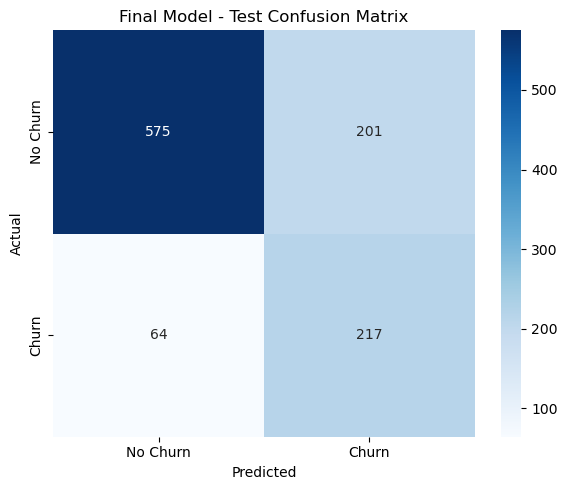

In [143]:
final_cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    final_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)

plt.title('Final Model - Test Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.tight_layout()
plt.show()



#  Saving the Final Model

I will save our final trained customer churn prediction pipeline.

The saved pipeline contains:
1. Numerical feature scaling.
2. Categorical feature encoding.
3. SMOTE processing.
4. Logistic Regression classifier.

Saving the complete pipeline allows us to use the same preprocessing steps during deployment.


In [144]:

import joblib
import os


os.makedirs("models", exist_ok=True)

print("Models directory created successfully.")


Models directory created successfully.


In [145]:
model_path = "models/customer_churn_pipeline.pkl"

joblib.dump(final_model, model_path)

print("Final model saved successfully!")
print("Saved location:", model_path)


Final model saved successfully!
Saved location: models/customer_churn_pipeline.pkl


In [146]:
loaded_model = joblib.load(model_path)


sample_predictions = loaded_model.predict(X_test.head(5))

print("Saved model loaded successfully.")

print("\nSample predictions:")
print(sample_predictions)


Saved model loaded successfully.

Sample predictions:
[1 0 0 0 0]



#  Customer Churn Prediction Function

I will create a reusable function that accepts customer information and predicts customer churn.

The function will return:

1. Churn prediction.
2. Churn probability.
3. Customer risk category (Low, Medium, or High).

The function will use our saved machine learning pipeline.

The same preprocessing steps used during model training will automatically be applied to new customer data.


In [147]:
required_features = X_train.columns.tolist()

print("Total required features:", len(required_features))

print("\nRequired customer features:")

for feature in required_features:
    print("-", feature)


Total required features: 19

Required customer features:
- gender
- SeniorCitizen
- Partner
- Dependents
- tenure
- PhoneService
- MultipleLines
- InternetService
- OnlineSecurity
- OnlineBackup
- DeviceProtection
- TechSupport
- StreamingTV
- StreamingMovies
- Contract
- PaperlessBilling
- PaymentMethod
- MonthlyCharges
- TotalCharges



### Creating a Reusable Prediction Function

I will create a function named predict_customer_churn().

It will:

- Accept customer information as a dictionary.
- Check whether all required features are provided.
- Convert the input into a DataFrame.
- Predict churn using the saved model.
- Calculate churn probability.
- Assign a risk category.

For this initial version, risk categories will use these probability ranges:

- Low Risk: Below 30%.
- Medium Risk: 30% to below 60%.
- High Risk: 60% or above.

These are initial application thresholds, not statistically calibrated risk bands. We can adjust them based on business requirements.


In [148]:

def predict_customer_churn(customer_data):


    missing_features = [
        feature for feature in required_features
        if feature not in customer_data
    ]

    if missing_features:
        raise ValueError(
            f"Missing customer features: {missing_features}"
        )


    customer_df = pd.DataFrame(
        [customer_data],
        columns=required_features
    )


    if customer_df.isnull().any().any():
        raise ValueError("Customer input contains missing values.")


    prediction = loaded_model.predict(customer_df)[0]


    probability = loaded_model.predict_proba(customer_df)[0][1]


    if probability < 0.30:
        risk_category = "Low Risk"

    elif probability < 0.60:
        risk_category = "Medium Risk"

    else:
        risk_category = "High Risk"


    result = {
        "Churn Prediction": (
            "Yes" if prediction == 1 else "No"
        ),
        "Churn Probability": round(float(probability) * 100, 2),
        "Risk Category": risk_category
    }

    return result


print("Customer churn prediction function created successfully.")


Customer churn prediction function created successfully.



### Testing with an Existing Customer Record

I will take one customer record from the test dataset and pass it to our prediction function.

This helps me  verify that the function accepts customer information and returns the expected prediction results.


In [150]:


print("Categorical features:")
print(categorical_features)

print("\nTraining data categorical types:")
print(X_train[categorical_features].dtypes)

print("\nSeniorCitizen values:")
print(X_train['SeniorCitizen'].unique())

# Inspect the fitted encoder categories

encoder = (
    loaded_model.named_steps['preprocessor']
    .named_transformers_['cat']
    .named_steps['encoder']
)

print("\nEncoder category data types:")

for feature, categories in zip(categorical_features, encoder.categories_):
    print(feature, categories.dtype)


Categorical features:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Training data categorical types:
gender              object
SeniorCitizen       object
Partner             object
Dependents          object
PhoneService        object
MultipleLines       object
InternetService     object
OnlineSecurity      object
OnlineBackup        object
DeviceProtection    object
TechSupport         object
StreamingTV         object
StreamingMovies     object
Contract            object
PaperlessBilling    object
PaymentMethod       object
dtype: object

SeniorCitizen values:
[0 1]

Encoder category data types:
gender object
SeniorCitizen object
Partner object
Dependents object
PhoneService object
MultipleLines object
InternetService object
OnlineSecurity object
OnlineBackup object
DevicePr


### Correcting the Final Model Pipeline

i am retraining only the selected Logistic Regression with SMOTE pipeline.

All categorical features will now use consistent string values.

The preprocessing pipeline, SMOTE and Logistic Regression will be fitted together again using the original training records.

I am not performing additional hyperparameter tuning.


In [151]:
X_train_fixed = X_train.copy()


for column in categorical_features:
    X_train_fixed[column] = X_train_fixed[column].astype(str)

print("Categorical data types standardized.")

print(X_train_fixed[categorical_features].dtypes)


Categorical data types standardized.
gender              object
SeniorCitizen       object
Partner             object
Dependents          object
PhoneService        object
MultipleLines       object
InternetService     object
OnlineSecurity      object
OnlineBackup        object
DeviceProtection    object
TechSupport         object
StreamingTV         object
StreamingMovies     object
Contract            object
PaperlessBilling    object
PaymentMethod       object
dtype: object


In [152]:

from sklearn.base import clone

final_model = clone(
    smote_model_pipelines['Logistic Regression']
)


final_model.fit(X_train_fixed, y_train)

print("Corrected final model trained successfully.")


Corrected final model trained successfully.


In [153]:
joblib.dump(
    final_model,
    "models/customer_churn_pipeline.pkl"
)


loaded_model = joblib.load(
    "models/customer_churn_pipeline.pkl"
)

print("Corrected model saved and loaded successfully.")


Corrected model saved and loaded successfully.


In [154]:

def predict_customer_churn(customer_data):

    missing_features = [
        feature for feature in required_features
        if feature not in customer_data
    ]

    if missing_features:
        raise ValueError(
            f"Missing customer features: {missing_features}"
        )


    customer_df = pd.DataFrame(
        [customer_data],
        columns=required_features
    )

    for column in categorical_features:
        customer_df[column] = customer_df[column].astype(str)


    if customer_df.isnull().any().any():
        raise ValueError("Customer input contains missing values.")

    prediction = loaded_model.predict(customer_df)[0]

    probability = loaded_model.predict_proba(customer_df)[0][1]

    if probability < 0.30:
        risk_category = "Low Risk"
    elif probability < 0.60:
        risk_category = "Medium Risk"
    else:
        risk_category = "High Risk"

    return {
        "Churn Prediction": "Yes" if prediction == 1 else "No",
        "Churn Probability": round(float(probability) * 100, 2),
        "Risk Category": risk_category
    }


print("Updated prediction function created successfully.")


Updated prediction function created successfully.


In [155]:
sample_customer = X_test.iloc[0].to_dict()

prediction_result = predict_customer_churn(sample_customer)

print("CUSTOMER CHURN PREDICTION")
print("-------------------------")

for key, value in prediction_result.items():
    print(f"{key}: {value}")


CUSTOMER CHURN PREDICTION
-------------------------
Churn Prediction: Yes
Churn Probability: 66.24
Risk Category: High Risk



#  Final Model Verification



In [156]:
X_test_fixed = X_test.copy()

for column in categorical_features:
    X_test_fixed[column] = X_test_fixed[column].astype(str)


y_test_pred = loaded_model.predict(X_test_fixed)

y_test_probability = loaded_model.predict_proba(X_test_fixed)[:, 1]


final_test_results = {
    'Accuracy': accuracy_score(y_test, y_test_pred),
    'Precision': precision_score(y_test, y_test_pred, zero_division=0),
    'Recall': recall_score(y_test, y_test_pred, zero_division=0),
    'F1 Score': f1_score(y_test, y_test_pred, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, y_test_probability)
}

print("CORRECTED FINAL MODEL TEST RESULTS")
print("----------------------------------")

for metric, score in final_test_results.items():
    print(f"{metric}: {score:.4f}")


CORRECTED FINAL MODEL TEST RESULTS
----------------------------------
Accuracy: 0.7493
Precision: 0.5191
Recall: 0.7722
F1 Score: 0.6209
ROC-AUC: 0.8441


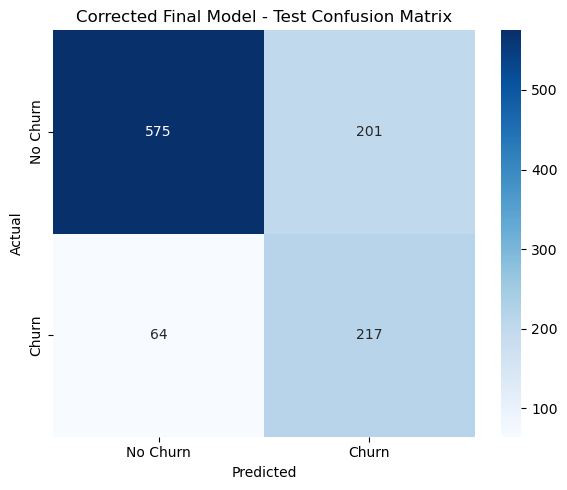

In [157]:
final_cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    final_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)

plt.title('Corrected Final Model - Test Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.tight_layout()
plt.show()


In [158]:
print("FINAL MODEL TEST RESULTS")
print("-" * 40)

for metric, value in final_test_results.items():
    print(f"{metric}: {value:.4f}")

FINAL MODEL TEST RESULTS
----------------------------------------
Accuracy: 0.7493
Precision: 0.5191
Recall: 0.7722
F1 Score: 0.6209
ROC-AUC: 0.8441
